# Virtual river gauges from satellite altimetry
# Stations hydrométriques virtuelles par altimétrie satellitaire

**Worked examples · Exemples traités :** Congo River at Kinshasa–Brazzaville (DR Congo) · fleuve Congo à Kinshasa–Brazzaville (RD Congo) — Rewa River, Viti Levu (Fiji) · rivière Rewa, Viti Levu (Fidji)

*Every result in this notebook comes from real satellite and model data, downloaded live from open services. Nothing is simulated.*
*Tous les résultats de ce notebook proviennent de vraies données satellitaires et de modèle, téléchargées en direct depuis des services ouverts. Rien n'est simulé.*

## About this notebook · À propos de ce notebook

**English**

This notebook is for hydrologists in national services who want to **measure river levels — and estimate discharge — where there is no working gauge**, using satellites. You will build a *virtual gauge* step by step on the Congo at Kinshasa, repeat it on the Rewa in Fiji, and then set it up for a river of your own.

**By the end you will be able to:**
1. explain how satellite altimeters measure water level, and why the heights are given relative to the geoid;
2. download real ICESat-2 and SWOT observations for any river, **with no account or password**;
3. clean the observations and build a water-level time series (a *virtual station*) with uncertainty;
4. combine two satellite missions and compare them with a ground gauge;
5. fit a stage–discharge **rating curve** with uncertainty, and judge whether it can be trusted;
6. export a virtual-gauge record your agency can use.

**How to use it.** Run the cells from top to bottom (*Shift + Enter*). Allow about 3 hours. Symbols used:

- ✏️ a cell you are expected to edit
- 🧪 *Try it* — a small experiment
- ⚠️ a common pitfall
- 💬 a question to discuss with colleagues

> **Français**
>
> Ce notebook s'adresse aux hydrologues des services nationaux qui veulent **mesurer le niveau des rivières — et estimer le débit — là où il n'existe pas de station en fonctionnement**, grâce aux satellites. Vous construirez pas à pas une *station virtuelle* sur le Congo à Kinshasa, vous la referez sur la Rewa aux Fidji, puis vous la mettrez en place pour votre propre rivière.
>
> **À la fin, vous saurez :**
> 1. expliquer comment un altimètre satellitaire mesure le niveau de l'eau, et pourquoi les hauteurs sont données par rapport au géoïde ;
> 2. télécharger de vraies observations ICESat-2 et SWOT pour n'importe quelle rivière, **sans compte ni mot de passe** ;
> 3. nettoyer les observations et construire une série temporelle de niveaux d'eau (une *station virtuelle*) avec son incertitude ;
> 4. combiner deux missions satellitaires et les comparer à une station au sol ;
> 5. ajuster une **courbe de tarage** hauteur–débit avec son incertitude, et juger si elle est fiable ;
> 6. exporter un enregistrement de station virtuelle utilisable par votre service.
>
> **Mode d'emploi.** Exécutez les cellules de haut en bas (*Maj + Entrée*). Comptez environ 3 heures. Symboles utilisés :
>
> - ✏️ une cellule à modifier
> - 🧪 *À vous* — une petite expérience
> - ⚠️ un piège fréquent
> - 💬 une question à discuter entre collègues

## Data used, accounts and licences · Données utilisées, comptes et licences

**English**

The core of the notebook needs **no account**. Optional sections use data you may already have (your agency's gauge records) or that need a free registration. Please credit the data providers when you use these results.

> **Français**
>
> Le cœur du notebook ne demande **aucun compte**. Les sections facultatives utilisent des données que vous avez peut-être déjà (les relevés de votre service) ou qui demandent une inscription gratuite. Merci de citer les fournisseurs de données lorsque vous utilisez ces résultats.

| Data · Données | What it gives · Ce que cela fournit | Account · Compte | Credit / licence |
|---|---|---|---|
| **ICESat-2 ATL13 v007** (NASA/NSIDC), via **SlideRule Earth** | Laser water heights along the satellite track · Hauteurs d'eau laser le long de la trace | None · Aucun | NASA open data, doi:10.5067/ATLAS/ATL13.007; SlideRule (University of Washington / NASA) |
| **SWOT RiverSP, Version D** (NASA/CNES, PO.DAAC), via **Hydrocron** | Water-surface elevation for each ~10 km river reach · Altitude de la surface de l'eau par tronçon de ~10 km | None · Aucun | NASA/CNES open data, PO.DAAC |
| **GEOGloWS v2** retrospective streamflow (ECMWF) | Modelled daily discharge (not Fiji) · Débit journalier modélisé (pas les Fidji) | None · Aucun | GEOGloWS ECMWF Streamflow Model v2 — open data |
| *Optional · Facultatif:* your agency gauge · votre station | Observed stage and discharge · Hauteurs et débits observés | — | Your agency's terms · Conditions de votre service |
| *Optional · Facultatif:* **GRDC** (Kinshasa 1147010) | Observed daily discharge (to 2010) · Débits journaliers observés (jusqu'en 2010) | Free registration; no redistribution · Inscription gratuite ; pas de rediffusion | Global Runoff Data Centre, Koblenz |
| *Optional · Facultatif:* **DAHITI** (TU Munich) | Long virtual-station records · Longues séries de stations virtuelles | Free API key · Clé API gratuite | CC BY 4.0 |

## Running the notebook · Exécuter le notebook

**English**

- **On your computer:** install Python 3.10+ and run `pip install -r requirements.txt` in this folder, then open the notebook in Jupyter or VS Code.
- **On Google Colab:** upload this notebook; the first code cell installs anything missing.
- The first run downloads a few megabytes and saves them in the `cache/` folder. Later runs reuse the cache, so the notebook still works **with a poor or no internet connection**. Set `REFRESH = True` to download the latest data again.
- Results are written to the `outputs/` folder. Optional gauge files go in the `data/` folder (see `data/README.md`).

> **Français**
>
> - **Sur votre ordinateur :** installez Python 3.10+ puis lancez `pip install -r requirements.txt` dans ce dossier, et ouvrez le notebook dans Jupyter ou VS Code.
> - **Sur Google Colab :** téléversez ce notebook ; la première cellule de code installe ce qui manque.
> - La première exécution télécharge quelques mégaoctets et les enregistre dans le dossier `cache/`. Les exécutions suivantes réutilisent ce cache : le notebook fonctionne donc **avec une connexion internet faible, voire absente**. Mettez `REFRESH = True` pour retélécharger les données les plus récentes.
> - Les résultats sont écrits dans le dossier `outputs/`. Les fichiers facultatifs de stations vont dans le dossier `data/` (voir `data/README.md`).

In [1]:
# --- Setup · Configuration ----------------------------------------------------
import importlib.util, subprocess, sys

# Install any missing packages (useful on Google Colab) · Installer les paquets manquants
for pkg in ["sliderule", "geopandas", "folium", "pyarrow", "scipy", "requests"]:
    if importlib.util.find_spec(pkg) is None:
        print(f"Installing · Installation : {pkg}")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

import io, json, logging, os, re, time, warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests
import folium
from shapely.geometry import shape
from shapely.geometry.polygon import orient
from scipy import stats

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

REFRESH = False   # ✏️ True = download everything again · True = tout retélécharger
CACHE = Path("cache");   CACHE.mkdir(exist_ok=True)
OUT   = Path("outputs"); OUT.mkdir(exist_ok=True)
DATA  = Path("data");    DATA.mkdir(exist_ok=True)
print("Ready · Prêt —", datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC"))

Ready · Prêt — 2026-11-03 21:18 UTC


In [2]:
# --- Figure style · Style des figures ------------------------------------------
# One colour per data source, used the same way in every figure.
# Une couleur par source de données, utilisée de la même façon dans toutes les figures.
COL = {"SWOT": "#2a78d6", "ICESat-2": "#eb6834", "Q": "#1baf7a",
       "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781",
       "grid": "#e1e0d9", "axis": "#c3c2b7", "bg": "#fcfcfb", "removed": "#b5b3ab"}
plt.rcParams.update({
    "figure.facecolor": COL["bg"], "axes.facecolor": COL["bg"], "savefig.facecolor": COL["bg"],
    "axes.edgecolor": COL["axis"], "axes.linewidth": 0.8, "axes.labelcolor": COL["ink2"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COL["grid"], "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": COL["axis"], "ytick.color": COL["axis"],
    "xtick.labelcolor": COL["ink2"], "ytick.labelcolor": COL["ink2"],
    "text.color": COL["ink"], "axes.titlesize": 12, "axes.titleweight": "bold", "axes.axisbelow": True,
    "axes.titlelocation": "left", "font.size": 10, "lines.linewidth": 1.6,
    "lines.solid_capstyle": "round", "legend.frameon": False, "figure.dpi": 110,
    "figure.figsize": (10, 4),
})

def dots(color, ms=6):
    """Filled marker with a thin light ring · Marqueur plein avec un fin anneau clair"""
    return dict(marker="o", ms=ms, mfc=color, mec=COL["bg"], mew=0.8, ls="none")

LEVEL_LABEL = "Water level · Niveau d'eau (m, EGM2008)"
Q_LABEL = "Discharge · Débit (m³/s)"

## Part A — How satellites measure river levels · Partie A — Comment les satellites mesurent le niveau des rivières

**English**

An **altimeter** measures the **distance (range)** between the satellite and the surface below, by timing a radar or laser pulse travelling down and back. The satellite's orbit is known to within a few centimetres, so the height of the water surface is:

> **height above the ellipsoid = orbit altitude − range − corrections**

The corrections allow for the pulse being slowed by the atmosphere (dry and wet troposphere, ionosphere) and for the tides of the solid Earth. The data producers apply them for you.

A height above the **ellipsoid** (a smooth mathematical model of the Earth, WGS84) is not what hydrologists use. We subtract the height of the **geoid** (*N*) — the shape that mean sea level would take if extended under the continents — to obtain an **orthometric height**, close to "metres above mean sea level". All the satellite data here use the **EGM2008** geoid:

> **H (orthometric) = h (ellipsoidal) − N (geoid)**

⚠️ A ground gauge reads from its own **gauge zero**, not from EGM2008. Satellite levels and gauge readings therefore differ by a constant that we estimate in Step 6.

> **Français**
>
> Un **altimètre** mesure la **distance (range)** entre le satellite et la surface, en chronométrant l'aller-retour d'une impulsion radar ou laser. L'orbite du satellite est connue à quelques centimètres près ; la hauteur de la surface de l'eau est donc :
>
> > **hauteur au-dessus de l'ellipsoïde = altitude de l'orbite − distance mesurée − corrections**
>
> Les corrections tiennent compte du ralentissement de l'impulsion dans l'atmosphère (troposphère sèche et humide, ionosphère) et des marées terrestres. Les producteurs des données les appliquent pour vous.
>
> Une hauteur au-dessus de l'**ellipsoïde** (modèle mathématique lisse de la Terre, WGS84) n'est pas celle qu'utilisent les hydrologues. On soustrait la hauteur du **géoïde** (*N*) — la forme que prendrait le niveau moyen des mers prolongé sous les continents — pour obtenir une **altitude orthométrique**, proche des « mètres au-dessus du niveau moyen de la mer ». Toutes les données satellitaires utilisées ici se réfèrent au géoïde **EGM2008** :
>
> > **H (orthométrique) = h (ellipsoïdale) − N (géoïde)**
>
> ⚠️ Une station au sol mesure à partir de son propre **zéro d'échelle**, et non par rapport à EGM2008. Les niveaux satellitaires et les lectures d'échelle diffèrent donc d'une constante, que nous estimerons à l'étape 6.

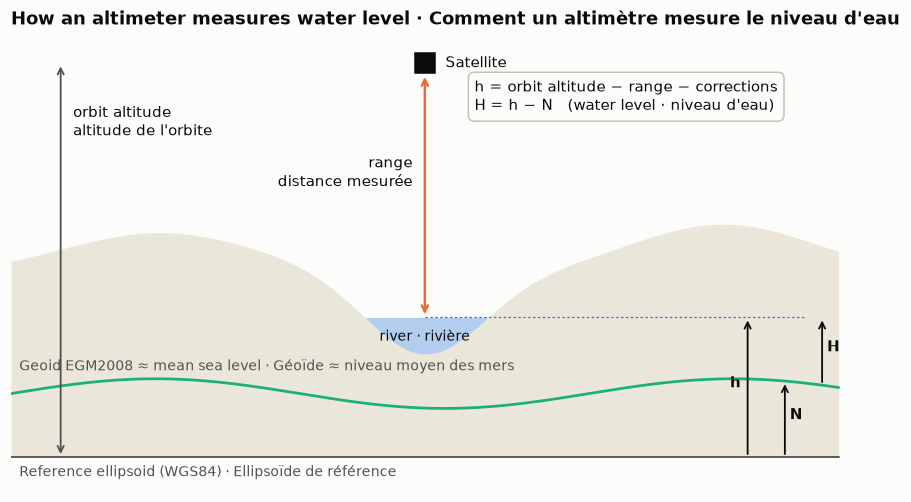

In [3]:
# Schematic (not to scale, not data) · Schéma (pas à l'échelle, pas des données)
fig, ax = plt.subplots(figsize=(10, 5.4))
x = np.linspace(0, 10, 500)
geoid = 1.5 + 0.35 * np.sin(0.9 * x)
ground = 4.3 + 1.0 * np.exp(-((x - 1.8) / 1.7) ** 2) + 1.2 * np.exp(-((x - 8.6) / 1.6) ** 2) \
         - 1.9 * np.exp(-((x - 5.0) / 1.0) ** 2)
water = 3.3
ax.fill_between(x, 0, ground, color="#ebe6da", lw=0)
ax.fill_between(x, np.minimum(ground, water), water, where=ground < water, color=COL["SWOT"], alpha=0.35, lw=0)
ax.plot(x, np.zeros_like(x), color=COL["ink2"], lw=1.2)
ax.plot(x, geoid, color=COL["Q"], lw=1.8)
ax.hlines(water, 5.0, 9.6, color=COL["SWOT"], lw=0.8, ls=(0, (2, 2)))
ax.plot(5.0, 9.3, marker="s", ms=13, color=COL["ink"])
ax.text(5.25, 9.3, "Satellite", va="center")
ax.annotate("", xy=(5.0, water), xytext=(5.0, 9.05),
            arrowprops=dict(arrowstyle="<->", color=COL["ICESat-2"], lw=1.6))
ax.text(4.85, 6.4, "range\ndistance mesurée", ha="right", color=COL["ink"])
ax.annotate("", xy=(0.6, 9.3), xytext=(0.6, 0), arrowprops=dict(arrowstyle="<->", color=COL["ink2"], lw=1.2))
ax.text(0.75, 7.6, "orbit altitude\naltitude de l'orbite", color=COL["ink"])
for xa, y0, y1, lab in [(8.9, 0, water, "h"), (9.35, 0, 1.5 + 0.35 * np.sin(0.9 * 9.35), "N"),
                        (9.8, 1.5 + 0.35 * np.sin(0.9 * 9.8), water, "H")]:
    ax.annotate("", xy=(xa, y1), xytext=(xa, y0), arrowprops=dict(arrowstyle="->", color=COL["ink"], lw=1.2))
    ax.text(xa - 0.08 if lab == "h" else xa + 0.06, (y0 + y1) / 2, lab, fontweight="bold",
            ha="right" if lab == "h" else "left")
ax.text(0.1, -0.45, "Reference ellipsoid (WGS84) · Ellipsoïde de référence", color=COL["ink2"], fontsize=9)
ax.text(0.1, 2.05, "Geoid EGM2008 ≈ mean sea level · Géoïde ≈ niveau moyen des mers", color=COL["ink2"], fontsize=9)
ax.text(5.0, water - 0.55, "river · rivière", ha="center", color=COL["ink"], fontsize=9)
ax.text(5.6, 8.2, "h = orbit altitude − range − corrections\nH = h − N   (water level · niveau d'eau)",
        fontsize=10, bbox=dict(fc=COL["bg"], ec=COL["axis"], boxstyle="round,pad=0.4"))
ax.set_xlim(0, 10.3); ax.set_ylim(-0.8, 10); ax.set_axis_off()
ax.set_title("How an altimeter measures water level · Comment un altimètre mesure le niveau d'eau")
plt.show()

## Three kinds of altimeter · Trois types d'altimètres

**English**

- **Nadir radar altimeters** (Jason-3, Sentinel-6, Sentinel-3A/B; earlier Envisat and SARAL) look straight down and measure along a thin line on the ground, the **ground track**. Their footprint is a few hundred metres to several kilometres, so land inside the footprint can spoil the measurement over narrow rivers.
- **ICESat-2** is a **laser** altimeter (launched 2018). It has 6 beams in 3 pairs about 3.3 km apart, with footprints only ~11–17 m wide, so it can measure small rivers. But clouds block the laser, and each track is repeated only every 91 days.
- **SWOT** (launched December 2022, science orbit since July 2023) is a **swath** radar altimeter. Its KaRIn instrument maps water heights across two 50 km-wide swaths. It sees most rivers wider than ~100 m, one to several times every 21 days, and NASA/CNES publish an average water level for each river **reach** (~10 km long).

A **virtual station** is a place where a satellite measures the same river repeatedly — where a ground track crosses the river, or a SWOT reach. Each satellite pass gives one water level. Together they form a time series, like a gauge read on irregular days.

💬 There is always a **trade-off**: missions with closely spaced tracks revisit each track rarely (ICESat-2: 91 days), while missions that revisit often have tracks far apart (Sentinel-6: 10 days, but ~315 km between tracks). Which matters more for the rivers you manage?

> **Français**
>
> - Les **altimètres radar au nadir** (Jason-3, Sentinel-6, Sentinel-3A/B ; auparavant Envisat et SARAL) visent à la verticale et mesurent le long d'une ligne fine au sol, la **trace au sol**. Leur empreinte va de quelques centaines de mètres à plusieurs kilomètres : sur une rivière étroite, la terre présente dans l'empreinte peut fausser la mesure.
> - **ICESat-2** est un altimètre **laser** (lancé en 2018). Il a 6 faisceaux en 3 paires espacées d'environ 3,3 km, avec des empreintes de seulement ~11–17 m : il peut donc mesurer de petites rivières. Mais les nuages arrêtent le laser, et chaque trace n'est répétée que tous les 91 jours.
> - **SWOT** (lancé en décembre 2022, orbite scientifique depuis juillet 2023) est un altimètre radar **à fauchée**. Son instrument KaRIn cartographie la hauteur de l'eau sur deux fauchées de 50 km de large. Il voit la plupart des rivières de plus de ~100 m de large, une à plusieurs fois tous les 21 jours, et la NASA et le CNES publient un niveau moyen pour chaque **tronçon** de rivière (~10 km de long).
>
> Une **station virtuelle** est un endroit où un satellite mesure la même rivière de façon répétée — là où une trace au sol croise la rivière, ou un tronçon SWOT. Chaque passage du satellite donne un niveau d'eau. Ensemble, ils forment une série temporelle, comme une échelle lue à des jours irréguliers.
>
> 💬 Il y a toujours un **compromis** : les missions aux traces rapprochées repassent rarement sur chaque trace (ICESat-2 : 91 jours), tandis que celles qui repassent souvent ont des traces très espacées (Sentinel-6 : 10 jours, mais ~315 km entre les traces). Qu'est-ce qui compte le plus pour les rivières que vous gérez ?

| Mission | Type | Repeat · Répétition | Track spacing at equator · Espacement à l'équateur | Footprint · Empreinte | Since · Depuis | Used here · Utilisé ici |
|---|---|---|---|---|---|---|
| Jason-3 | Radar, nadir | 10 days (repeat orbit until 2025) | ~315 km | several km · plusieurs km | 2016 | — |
| Sentinel-6 MF | Radar, nadir (SAR) | 10 days | ~315 km | ~0.3 km along track | 2020 | — |
| Sentinel-3A/B | Radar, nadir (SAR) | 27 days | ~104 km each · chacun | ~0.3 km along track | 2016/2018 | — |
| **ICESat-2** | Laser, 6 beams · 6 faisceaux | 91 days | ~29 km | ~11–17 m | 2018 | **Yes · Oui** |
| **SWOT** | Radar swath · à fauchée (KaRIn) | 21 days | 2 × 50 km swaths · fauchées | pixels of tens of m · pixels de quelques dizaines de m | 2023 | **Yes · Oui** |

*Sentinel-3 data need a free Copernicus account; DAHITI and Hydroweb.next distribute ready-made radar virtual stations (see Step 5).*
*Les données Sentinel-3 demandent un compte Copernicus gratuit ; DAHITI et Hydroweb.next distribuent des stations virtuelles radar prêtes à l'emploi (voir l'étape 5).*

## Why the Congo and the Rewa are so different · Pourquoi le Congo et la Rewa sont si différents

**English**

| | Congo at Kinshasa | Rewa (Viti Levu) |
|---|---|---|
| Width | 2–5 km | 100–400 m |
| Flood wave | slow and seasonal — rises and falls over months | fast — cyclone floods last hours to a few days |
| Lower reach | controlled by the rapids just downstream of Kinshasa | tidal near Nausori and the delta |
| What satellites see | almost every flood cycle, from several missions | many floods fall between satellite passes |

The same method works on both rivers, but the results — and how far you can trust them — will be very different. Keep this contrast in mind as you go.

> **Français**
>
> | | Congo à Kinshasa | Rewa (Viti Levu) |
> |---|---|---|
> | Largeur | 2–5 km | 100–400 m |
> | Onde de crue | lente et saisonnière — monte et descend sur plusieurs mois | rapide — les crues cycloniques durent de quelques heures à quelques jours |
> | Partie aval | contrôlée par les rapides juste en aval de Kinshasa | soumise à la marée près de Nausori et dans le delta |
> | Ce que voient les satellites | presque chaque cycle de crue, par plusieurs missions | beaucoup de crues passent entre deux passages |
>
> La même méthode fonctionne sur les deux rivières, mais les résultats — et la confiance qu'on peut leur accorder — seront très différents. Gardez ce contraste en tête tout au long du notebook.

## Part B — Build a virtual gauge, step by step (Congo at Kinshasa) · Partie B — Construire une station virtuelle pas à pas (Congo à Kinshasa)

**English**

### Configure the site
All the choices for a site are kept in one place, the `SITES` dictionary below. Two sites are ready to use. In Part D you will add your own.

| Setting | Meaning |
|---|---|
| `lat`, `lon` | approximate location of the virtual station |
| `swot_reach` | ID of the SWOT river reach (from the SWORD river database, version 17b) |
| `swot_up`, `swot_down` | the neighbouring reaches upstream and downstream, used for a consistency check |
| `mask_width_m`, `mask_frac` | typical water width, and the share of it used to draw the water mask around the river centre-line |
| `h_range` | the range of water levels (m, EGM2008) that is physically possible here — anything outside is an error |
| `slope_correction` | whether to correct ICESat-2 points for the slope of the water surface along the reach |
| `geoglows_id` | GEOGloWS model river ID, for modelled discharge (`None` if not available) |
| `gauge_file` | optional CSV of your own gauge data |

> **Français**
>
> ### Configurer le site
> Tous les choix relatifs à un site sont regroupés au même endroit : le dictionnaire `SITES` ci-dessous. Deux sites sont prêts à l'emploi. Dans la partie D, vous ajouterez le vôtre.
>
> | Paramètre | Signification |
> |---|---|
> | `lat`, `lon` | position approximative de la station virtuelle |
> | `swot_reach` | identifiant du tronçon SWOT (base de données de rivières SWORD, version 17b) |
> | `swot_up`, `swot_down` | les tronçons voisins en amont et en aval, utilisés pour un contrôle de cohérence |
> | `mask_width_m`, `mask_frac` | largeur typique du plan d'eau, et la part de celle-ci utilisée pour tracer le masque d'eau autour de la ligne centrale |
> | `h_range` | la plage de niveaux d'eau (m, EGM2008) physiquement possible ici — toute valeur en dehors est une erreur |
> | `slope_correction` | corriger ou non les points ICESat-2 de la pente de la surface de l'eau le long du tronçon |
> | `geoglows_id` | identifiant de rivière du modèle GEOGloWS, pour le débit modélisé (`None` si indisponible) |
> | `gauge_file` | fichier CSV facultatif de votre propre station |

In [4]:
# ✏️ Site settings · Paramètres des sites
SITES = {
    "congo_kinshasa": dict(
        name="Congo River at Kinshasa–Brazzaville (DR Congo) · Fleuve Congo à Kinshasa–Brazzaville (RD Congo)",
        short="Congo – Kinshasa",
        lat=-4.270, lon=15.336,
        swot_reach="13217000081",      # Kinshasa–Brazzaville reach · tronçon Kinshasa–Brazzaville
        swot_up="13217000101",         # Pool Malebo (upstream · amont)
        swot_down="13217000071",       # towards the rapids (downstream · aval)
        mask_width_m=3600, mask_frac=0.45,
        h_range=(260, 280),
        slope_correction=True,
        geoglows_id=130798640,         # main stem, checked by hand · tronçon principal, vérifié à la main
        gauge_file=DATA / "gauge_congo_kinshasa.csv",
        dahiti_ids=[12153, 13227],     # optional (needs API key) · facultatif (clé API)
        t0="2018-10-14",               # start of ICESat-2 data · début des données ICESat-2
    ),
    "rewa_fiji": dict(
        name="Rewa River, Viti Levu (Fiji) · Rivière Rewa, Viti Levu (Fidji)",
        short="Rewa – Fiji",
        lat=-17.961, lon=178.435,
        swot_reach="55200000051",      # ~10–25 km upstream of Nausori · ~10–25 km en amont de Nausori
        swot_up="55200000061",
        swot_down="55200000041",
        mask_width_m=150, mask_frac=0.6,
        h_range=(-3, 20),
        slope_correction=True,
        geoglows_id=None,              # Fiji is not in GEOGloWS v2 · les Fidji ne sont pas dans GEOGloWS v2
        gauge_file=DATA / "gauge_rewa_fiji.csv",
        dahiti_ids=[],
        t0="2018-10-14",
    ),
}

SITE_KEY = "congo_kinshasa"    # ✏️
SITE = SITES[SITE_KEY]
print(SITE["name"])

Congo River at Kinshasa–Brazzaville (DR Congo) · Fleuve Congo à Kinshasa–Brazzaville (RD Congo)


## Step 0 — Where is the river? · Étape 0 — Où est la rivière ?

**English**

Before using any satellite data we need the **shape of the river**. SWOT reaches come from the SWORD river database, which stores a centre-line for every river wider than ~30 m. We download the centre-line of our reach from **Hydrocron** (NASA's open SWOT time-series service) and widen it into a **water mask**: a polygon that covers the channel but not the banks.

⚠️ Make the mask a little narrower than the river. Points on the banks and the floodplain look like water to the satellite processing, but they are usually higher than the water and will spoil your levels.

> **Français**
>
> Avant d'utiliser des données satellitaires, il nous faut la **forme de la rivière**. Les tronçons SWOT proviennent de la base de données SWORD, qui contient une ligne centrale pour chaque rivière de plus de ~30 m de large. Nous téléchargeons la ligne centrale de notre tronçon depuis **Hydrocron** (le service ouvert de séries temporelles SWOT de la NASA) et nous l'élargissons en un **masque d'eau** : un polygone qui couvre le chenal mais pas les berges.
>
> ⚠️ Faites un masque un peu plus étroit que la rivière. Les points sur les berges et la plaine d'inondation ressemblent à de l'eau pour le traitement satellitaire, mais ils sont généralement plus hauts que l'eau et faussent les niveaux.

In [5]:
# --- Download helpers · Outils de téléchargement --------------------------------
HYDROCRON = "https://soto.podaac.earthdatacloud.nasa.gov/hydrocron/v1/timeseries"
LOG = CACHE / "download_log.json"

def log_download(name, source):
    """Record what was downloaded, from where and when · Noter quoi, d'où et quand"""
    log = json.loads(LOG.read_text()) if LOG.exists() else {}
    log[name] = {"source": source, "downloaded_utc": datetime.now(timezone.utc).isoformat(timespec="seconds")}
    LOG.write_text(json.dumps(log, indent=1))

def http_get(url, params=None, timeout=120, tries=3):
    """GET request with a few retries · Requête GET avec quelques nouvelles tentatives"""
    for i in range(tries):
        try:
            r = requests.get(url, params=params, timeout=timeout)
            if r.status_code < 500:
                return r
        except requests.RequestException as e:
            print(f"  retry · nouvel essai ({e.__class__.__name__})")
        time.sleep(3 * (i + 1))
    raise RuntimeError(f"Download failed · Échec du téléchargement : {url}")

def utc_naive(x):
    """Convert times to UTC without time-zone · Convertir les dates en UTC sans fuseau"""
    t = pd.to_datetime(x, utc=True, errors="coerce")
    if isinstance(t, pd.Series):
        return t.dt.tz_convert(None).dt.as_unit("ns")
    return t.tz_convert(None).as_unit("ns")

def today():
    return pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%d")

def reach_line(reach_id, refresh=REFRESH):
    """Centre-line of a SWOT/SWORD reach (from Hydrocron GeoJSON) · Ligne centrale d'un tronçon"""
    f = CACHE / f"swot_reach_{reach_id}_line.geojson"
    if f.exists() and not refresh:
        return gpd.read_file(f)
    params = dict(feature="Reach", feature_id=reach_id, output="geojson",
                  fields="reach_id,time_str,river_name,p_width,p_length,geometry",
                  start_time="2023-07-01T00:00:00Z", end_time=f"{today()}T23:59:59Z")
    r = http_get(HYDROCRON, params)
    r.raise_for_status()
    feats = [ft for ft in r.json()["results"]["geojson"]["features"]
             if ft.get("geometry") and ft["geometry"].get("coordinates")]
    props = {k: feats[0]["properties"].get(k) for k in ["reach_id", "river_name", "p_width", "p_length"]}
    gdf = gpd.GeoDataFrame([props], geometry=[shape(feats[0]["geometry"])], crs=4326)
    gdf.to_file(f, driver="GeoJSON")
    log_download(f.name, r.url)
    return gdf

def channel_mask(line_gdf, width_m, frac):
    """Widen the centre-line into a water-mask polygon · Élargir la ligne centrale en masque d'eau"""
    utm = line_gdf.estimate_utm_crs()                       # metric map projection · projection métrique
    line_utm = line_gdf.to_crs(utm).geometry.iloc[0]
    mask_utm = line_utm.buffer(width_m * frac, cap_style="flat")
    mask_ll = gpd.GeoSeries([mask_utm], crs=utm).to_crs(4326).iloc[0]
    mask_ll = orient(mask_ll.simplify(0.0003), 1.0)         # few vertices, anticlockwise · peu de sommets
    return dict(utm=utm, line_utm=line_utm, mask_utm=mask_utm, mask_ll=mask_ll,
                length_km=line_utm.length / 1000)

In [6]:
line = reach_line(SITE["swot_reach"])
geo = channel_mask(line, SITE["mask_width_m"], SITE["mask_frac"])
print(f"Reach · Tronçon {SITE['swot_reach']} — river · rivière : {line.river_name.iloc[0]}")
print(f"Length · Longueur : {geo['length_km']:.1f} km ; mask width · largeur du masque : "
      f"{2 * SITE['mask_width_m'] * SITE['mask_frac'] / 1000:.1f} km")

Reach · Tronçon 13217000081 — river · rivière : Congo
Length · Longueur : 9.2 km ; mask width · largeur du masque : 3.2 km


In [7]:
def site_map(site, geo, points=None, max_points=800):
    """Interactive map: mask, centre-line and (optionally) satellite points · Carte interactive"""
    m = folium.Map(location=[site["lat"], site["lon"]], zoom_start=12, tiles=None)
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
        attr="Esri, Maxar, Earthstar Geographics", name="Satellite image · Image satellite").add_to(m)
    folium.TileLayer("OpenStreetMap", name="OpenStreetMap").add_to(m)
    folium.GeoJson(geo["mask_ll"].__geo_interface__, name="Water mask · Masque d'eau",
                   style_function=lambda f: {"color": "#ffffff", "weight": 1.5, "fillOpacity": 0.05}).add_to(m)
    cl = gpd.GeoSeries([geo["line_utm"]], crs=geo["utm"]).to_crs(4326).iloc[0]
    folium.GeoJson(cl.__geo_interface__, name="SWOT reach centre-line · Ligne centrale",
                   style_function=lambda f: {"color": COL["SWOT"], "weight": 3}).add_to(m)
    if points is not None and len(points):
        pts = points.to_crs(4326)
        pts = pts.sample(min(max_points, len(pts)), random_state=0)
        fg = folium.FeatureGroup(name="ICESat-2 points")
        for gx, gy in zip(pts.geometry.x, pts.geometry.y):
            folium.CircleMarker([gy, gx], radius=2, color=COL["ICESat-2"], fill=True, weight=0,
                                fill_opacity=0.9).add_to(fg)
        fg.add_to(m)
    folium.Marker([site["lat"], site["lon"]], tooltip=site["short"]).add_to(m)
    folium.LayerControl().add_to(m)
    return m

site_map(SITE, geo)

## Step 1 — Download the raw ICESat-2 points · Étape 1 — Télécharger les points ICESat-2 bruts

**English**

**ICESat-2 ATL13** is NASA's inland-water product: every ~30–100 m along each laser beam it gives a water-surface height. We ask the **SlideRule** service to cut out only the points inside our water mask, for every pass since October 2018. SlideRule does the heavy work on its own servers, so only a few megabytes come back, and **no login is needed**.

Each row returned is one water-surface segment. The columns we use are:

| Column | Meaning |
|---|---|
| `ht_ortho` | water height above the EGM2008 geoid (m) |
| `rgt`, `cycle` | reference ground track and cycle number — together they identify a pass |
| `gt` | which of the 6 beams |
| `inland_water_body_type` | 5 = river, 1 = lake, 6 = estuary, 7 = coastal |
| `cloud_flag_asr_atl09` | cloud test from the atmosphere product: 0–2 = probably clear, 3–5 = probably cloudy |
| `stdev_water_surf` | roughness of the water surface in the segment (m) |

> **Français**
>
> **ICESat-2 ATL13** est le produit « eaux continentales » de la NASA : tous les ~30–100 m le long de chaque faisceau laser, il fournit une hauteur de la surface de l'eau. Nous demandons au service **SlideRule** de découper uniquement les points situés dans notre masque d'eau, pour tous les passages depuis octobre 2018. SlideRule fait le gros du travail sur ses propres serveurs : seuls quelques mégaoctets sont renvoyés, et **aucun identifiant n'est nécessaire**.
>
> Chaque ligne renvoyée est un segment de surface d'eau. Les colonnes utilisées sont :
>
> | Colonne | Signification |
> |---|---|
> | `ht_ortho` | hauteur de l'eau au-dessus du géoïde EGM2008 (m) |
> | `rgt`, `cycle` | trace de référence au sol et numéro de cycle — ensemble, ils identifient un passage |
> | `gt` | lequel des 6 faisceaux |
> | `inland_water_body_type` | 5 = rivière, 1 = lac, 6 = estuaire, 7 = côtier |
> | `cloud_flag_asr_atl09` | test de nuages du produit atmosphère : 0–2 = probablement dégagé, 3–5 = probablement nuageux |
> | `stdev_water_surf` | rugosité de la surface de l'eau dans le segment (m) |

In [8]:
ATL13_EXTRA = ["inland_water_body_type", "cloud_flag_asr_atl09"]
_sliderule_ready = False

class _Collect(logging.Handler):
    """Collect SlideRule server messages instead of printing them · Collecter les messages du serveur"""
    def __init__(self):
        super().__init__()
        self.messages = []
    def emit(self, record):
        self.messages.append(record.getMessage())

def fetch_atl13(site_key, mask_ll, t0, t1=None, refresh=REFRESH):
    """ICESat-2 ATL13 points inside the water mask (SlideRule, no login).
    Points ICESat-2 ATL13 dans le masque d'eau (SlideRule, sans identifiant)."""
    global _sliderule_ready
    f = CACHE / f"atl13_{site_key}.parquet"
    if f.exists() and not refresh:
        return gpd.read_parquet(f)
    from sliderule import sliderule
    if not _sliderule_ready:
        sliderule.init(verbose=False, loglevel=logging.CRITICAL)
        _sliderule_ready = True
    poly = [{"lon": x, "lat": y} for x, y in mask_ll.exterior.coords]
    collector = _Collect()                         # keep server messages quiet · messages du serveur
    lg = logging.getLogger("sliderule"); lg.addHandler(collector); lg.propagate = False
    try:
        gdf = sliderule.run("atl13x", {"poly": poly, "t0": f"{t0}T00:00:00Z", "t1": f"{t1 or today()}T23:59:59Z",
                                       "atl13": {"anc_fields": ATL13_EXTRA}})
    finally:
        lg.removeHandler(collector)
    failed = sorted({m.group(1) for m in (re.search(r"resource (\S+\.h5)", t) for t in collector.messages) if m})
    if failed:
        print(f"⚠️ {len(failed)} ICESat-2 file(s) could not be read by the server and were skipped · "
              f"fichier(s) illisible(s), ignoré(s) : {failed}")
    gdf.to_parquet(f)
    log_download(f.name, "SlideRule atl13x — ICESat-2 ATL13 v007")
    return gdf

raw = fetch_atl13(SITE_KEY, geo["mask_ll"], SITE["t0"])
n_pass = raw.groupby(["rgt", "cycle"]).ngroups
print(f"{len(raw):,} points from · issus de {n_pass} passes · passages, "
      f"{raw.index.min():%Y-%m-%d} → {raw.index.max():%Y-%m-%d}")
raw[["rgt", "cycle", "gt", "ht_ortho", "inland_water_body_type", "cloud_flag_asr_atl09", "stdev_water_surf"]].head()

6,520 points from · issus de 27 passes · passages, 2018-11-11 → 2025-12-08


,rgt,cycle,gt,ht_ortho,inland_water_body_type,cloud_flag_asr_atl09,stdev_water_surf
time_ns,,,,,,,
2019-02-10 08:52:59.004774144,669,2,20,269.485596,5,0,0.025
2019-02-10 08:52:59.006473984,669,2,20,269.476227,5,0,0.025
2019-02-10 08:52:59.008073984,669,2,20,269.478516,5,0,0.025
2019-02-10 08:52:59.009774336,669,2,20,269.474152,5,0,0.025
2019-02-10 08:52:59.011474176,669,2,20,269.477081,5,0,0.025


In [9]:
site_map(SITE, geo, points=raw)

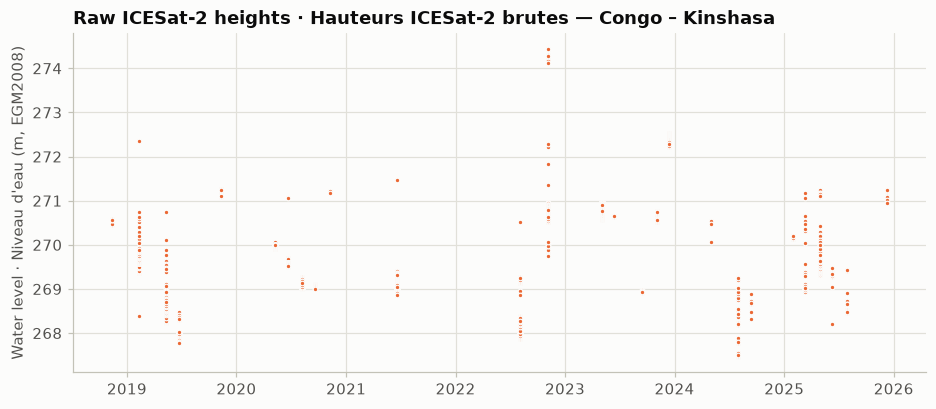

In [10]:
fig, ax = plt.subplots()
ax.plot(raw.index, raw.ht_ortho, **dots(COL["ICESat-2"], ms=3))
ax.set_ylabel(LEVEL_LABEL)
ax.set_title(f"Raw ICESat-2 heights · Hauteurs ICESat-2 brutes — {SITE['short']}")
plt.show()

**English**

Most points form a clear band — that is the river. But some points sit many metres above it.

💬 What could make a laser "see" a surface 10–40 m above the river? (Think about the weather, and about the river banks.)

> **Français**
>
> La plupart des points forment une bande nette — c'est la rivière. Mais certains points se trouvent plusieurs mètres au-dessus.
>
> 💬 Qu'est-ce qui pourrait faire « voir » au laser une surface 10 à 40 m au-dessus de la rivière ? (Pensez à la météo, et aux berges.)

## Step 2 — Clean the points · Étape 2 — Nettoyer les points

**English**

We remove points in four steps, and keep a note of **why** each point was removed, so that you can check the decisions:

1. **Physically impossible** — outside `h_range` for this site.
2. **Not a river** — `inland_water_body_type` ≠ 5.
3. **Cloudy** — `cloud_flag_asr_atl09` > 2. The laser may have reflected from cloud tops.
4. **Outliers within a pass** — points far from the other points of the same pass, using the *median absolute deviation* (MAD). The MAD is like a standard deviation, but it is not pulled around by the outliers themselves. A point is removed if it is more than `k_mad` × MAD from the pass median. The limit is never narrower than ±45 cm (3 × 15 cm), because the water surface itself slopes along the reach and one pass can cover several kilometres.

We also compute each point's **distance along the river** (km, measured upstream from the downstream end of the reach). We need it in Step 3.

> **Français**
>
> Nous retirons des points en quatre étapes, en notant **pourquoi** chaque point est retiré, pour que vous puissiez vérifier les décisions :
>
> 1. **Physiquement impossible** — en dehors de `h_range` pour ce site.
> 2. **Pas une rivière** — `inland_water_body_type` ≠ 5.
> 3. **Nuageux** — `cloud_flag_asr_atl09` > 2. Le laser a pu se réfléchir sur le sommet des nuages.
> 4. **Valeurs aberrantes dans un passage** — points éloignés des autres points du même passage, selon l'*écart absolu médian* (MAD). Le MAD ressemble à un écart-type, mais il n'est pas influencé par les valeurs aberrantes elles-mêmes. Un point est retiré s'il est à plus de `k_mad` × MAD de la médiane du passage. La limite n'est jamais plus étroite que ±45 cm (3 × 15 cm), car la surface de l'eau elle-même est en pente le long du tronçon et un passage peut couvrir plusieurs kilomètres.
>
> Nous calculons aussi la **distance le long de la rivière** de chaque point (km, mesurée vers l'amont depuis l'extrémité aval du tronçon). Elle servira à l'étape 3.

In [11]:
def robust_spread(x):
    """1.4826 × MAD ≈ standard deviation for well-behaved data · ≈ écart-type pour des données régulières"""
    x = np.asarray(x, float)
    return 1.4826 * np.median(np.abs(x - np.median(x)))

def prepare_atl13(gdf, geo, h_range=None, max_cloud=2, k_mad=3.0, min_spread=0.15):
    """Label every ICESat-2 point as kept or removed (with the reason), add distance along the river.
    Étiqueter chaque point ICESat-2 (gardé ou retiré, avec la raison), ajouter la distance le long de la rivière."""
    p = gdf.to_crs(geo["utm"]).reset_index()
    p = p[p.within(geo["mask_utm"])].reset_index(drop=True)
    p["time"] = utc_naive(p["time_ns"] if "time_ns" in p else p[p.columns[0]])
    p["s_km"] = [geo["line_utm"].project(pt) / 1000 for pt in p.geometry]
    p["pass_id"] = p["time"].dt.strftime("%Y-%m-%d") + "_rgt" + p["rgt"].astype(str)
    p["reason"] = "kept"
    lo, hi = h_range or (-np.inf, np.inf)
    p.loc[(p.ht_ortho < lo) | (p.ht_ortho > hi), "reason"] = "1 impossible level"
    kept = p.reason == "kept"
    p.loc[kept & (p.inland_water_body_type != 5), "reason"] = "2 not river"
    kept = p.reason == "kept"
    p.loc[kept & (p.cloud_flag_asr_atl09 > max_cloud), "reason"] = "3 cloudy"
    kept = p.reason == "kept"
    grp = p[kept].groupby("pass_id").ht_ortho
    med, spr = grp.transform("median"), grp.transform(robust_spread)
    outlier = (p.loc[kept, "ht_ortho"] - med).abs() > k_mad * np.maximum(spr, min_spread)
    p.loc[outlier.index[outlier], "reason"] = "4 outlier in pass"
    return p

pts = prepare_atl13(raw, geo, h_range=SITE["h_range"])
pts.reason.value_counts().rename("points").to_frame()

,points
reason,
kept,6225
3 cloudy,149
4 outlier in pass,133


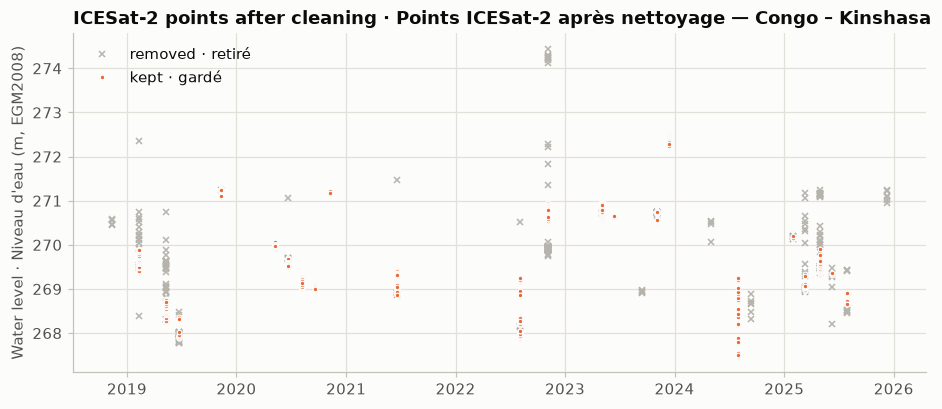

In [12]:
fig, ax = plt.subplots()
rem, kep = pts[pts.reason != "kept"], pts[pts.reason == "kept"]
ax.plot(rem.time, rem.ht_ortho, marker="x", ms=4, ls="none", color=COL["removed"], label="removed · retiré")
ax.plot(kep.time, kep.ht_ortho, **dots(COL["ICESat-2"], ms=3), label="kept · gardé")
ax.set_ylabel(LEVEL_LABEL); ax.legend(loc="upper left")
ax.set_title(f"ICESat-2 points after cleaning · Points ICESat-2 après nettoyage — {SITE['short']}")
plt.show()

**English**

🧪 **Try it.** Change `k_mad` (e.g. 2 or 5) or `max_cloud` (e.g. 5 = keep everything) in `prepare_atl13(...)` and run the two cells again. How many points change category? Do the outliers come back?

> **Français**
>
> 🧪 **À vous.** Modifiez `k_mad` (par ex. 2 ou 5) ou `max_cloud` (par ex. 5 = tout garder) dans `prepare_atl13(...)` et relancez les deux cellules. Combien de points changent de catégorie ? Les valeurs aberrantes reviennent-elles ?

## Step 3 — From points to one level per pass · Étape 3 — Des points à un niveau par passage

**English**

A river surface is not flat: it slopes downhill. ICESat-2 tracks run roughly north–south and drift a little from one pass to the next, so each pass crosses the reach **at a different distance along the river**. If the water surface falls by 10 cm per km, two passes 5 km apart differ by 50 cm even when the river level has not changed at all.

So we:
1. measure the **water-surface slope** within each pass that covers at least 2 km of river, using a robust line fit (Theil–Sen);
2. take the median slope of all passes;
3. shift every point to the **middle of the reach** — the same point that SWOT reports — using that slope;
4. take the **median** of each pass as its water level, and the spread of the points to estimate its uncertainty.

> **Français**
>
> La surface d'une rivière n'est pas plate : elle descend vers l'aval. Les traces ICESat-2 sont orientées à peu près nord–sud et se décalent un peu d'un passage à l'autre ; chaque passage croise donc le tronçon **à une distance différente le long de la rivière**. Si la surface de l'eau descend de 10 cm par km, deux passages distants de 5 km diffèrent de 50 cm alors que le niveau de la rivière n'a pas changé.
>
> Nous allons donc :
> 1. mesurer la **pente de la surface de l'eau** dans chaque passage couvrant au moins 2 km de rivière, avec un ajustement de droite robuste (Theil–Sen) ;
> 2. prendre la pente médiane de tous les passages ;
> 3. ramener chaque point au **milieu du tronçon** — le même point que celui donné par SWOT — grâce à cette pente ;
> 4. prendre la **médiane** de chaque passage comme niveau d'eau, et la dispersion des points pour estimer son incertitude.

In [13]:
def estimate_slope(p, min_points=20, min_span_km=2.0):
    """Water-surface slope (m/km, positive = rising upstream) for each long-enough pass.
    Pente de la surface de l'eau (m/km, positive = montée vers l'amont) pour chaque passage assez long."""
    rows = []
    for pid, g in p[p.reason == "kept"].groupby("pass_id"):
        span = g.s_km.max() - g.s_km.min()
        if len(g) >= min_points and span >= min_span_km:
            rows.append(dict(pass_id=pid, slope_m_per_km=stats.theilslopes(g.ht_ortho, g.s_km)[0],
                             n_points=len(g), span_km=span))
    return pd.DataFrame(rows, columns=["pass_id", "slope_m_per_km", "n_points", "span_km"])

slopes = estimate_slope(pts)
SLOPE = slopes.slope_m_per_km.median() if (SITE["slope_correction"] and len(slopes)) else 0.0
print(f"Median slope · Pente médiane : {SLOPE * 100:.1f} cm/km  (from · à partir de {len(slopes)} passes)")
slopes.round(3)

Median slope · Pente médiane : 8.1 cm/km  (from · à partir de 10 passes)


,pass_id,slope_m_per_km,n_points,span_km
0,2019-02-10_rgt669,0.106,1109,4.356
1,2019-05-12_rgt669,0.116,279,4.262
2,2019-11-09_rgt669,0.017,49,2.695
3,2021-06-18_rgt1301,0.129,259,4.544
4,2022-08-04_rgt669,0.082,94,4.262
5,2022-11-03_rgt669,0.051,1072,4.262
6,2023-05-04_rgt669,0.057,999,4.262
7,2023-12-13_rgt1301,0.081,630,2.175
8,2024-07-31_rgt669,0.343,49,4.262
9,2025-04-29_rgt669,0.008,360,7.355


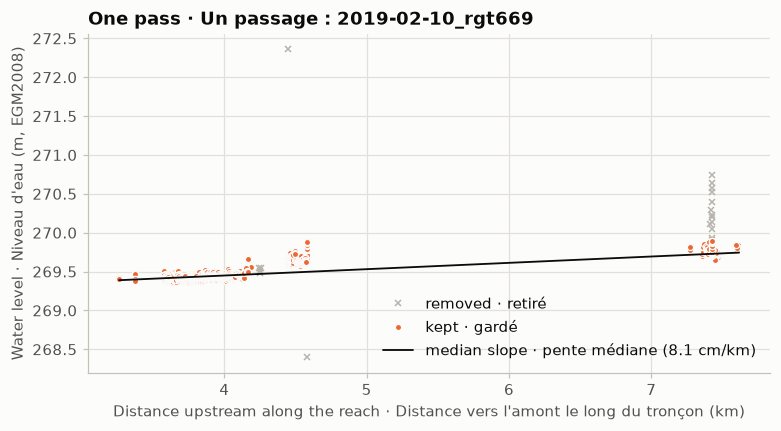

In [14]:
# The pass with the most points: heights along the river · Le passage le plus riche : hauteurs le long de la rivière
best = pts[pts.reason == "kept"].pass_id.value_counts().idxmax()
g = pts[pts.pass_id == best]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(g[g.reason != "kept"].s_km, g[g.reason != "kept"].ht_ortho, marker="x", ms=4, ls="none",
        color=COL["removed"], label="removed · retiré")
ax.plot(g[g.reason == "kept"].s_km, g[g.reason == "kept"].ht_ortho, **dots(COL["ICESat-2"], ms=4), label="kept · gardé")
xs = np.linspace(g.s_km.min(), g.s_km.max(), 10)
k = g[g.reason == "kept"]
ax.plot(xs, np.median(k.ht_ortho) + SLOPE * (xs - np.median(k.s_km)), color=COL["ink"], lw=1.2,
        label=f"median slope · pente médiane ({SLOPE * 100:.1f} cm/km)")
ax.set_xlabel("Distance upstream along the reach · Distance vers l'amont le long du tronçon (km)")
ax.set_ylabel(LEVEL_LABEL); ax.legend()
ax.set_title(f"One pass · Un passage : {best}")
plt.show()

In [15]:
def per_pass_levels(p, slope_m_per_km, s_ref_km, min_points=5, u_floor=0.10):
    """One water level per satellite pass: the virtual-station time series.
    Un niveau d'eau par passage : la série temporelle de la station virtuelle.
    u_floor: allowance (m) for errors that do not average out (beam biases, slope correction).
    u_floor : marge (m) pour les erreurs qui ne se moyennent pas (biais des faisceaux, correction de pente)."""
    k = p[p.reason == "kept"].copy()
    k["h_corr"] = k.ht_ortho - slope_m_per_km * (k.s_km - s_ref_km)
    vs = (k.groupby("pass_id")
            .agg(time=("time", "median"), wse_m=("h_corr", "median"), n_points=("h_corr", "size"),
                 spread_m=("h_corr", robust_spread), span_km=("s_km", lambda s: s.max() - s.min()))
            .reset_index())
    vs = vs[vs.n_points >= min_points].sort_values("time").reset_index(drop=True)
    vs["wse_u_m"] = np.sqrt((1.253 * vs.spread_m) ** 2 / vs.n_points + u_floor ** 2)
    vs["source"] = "ICESat-2"
    return vs

vs_ice = per_pass_levels(pts, SLOPE, s_ref_km=geo["length_km"] / 2)
print(f"{len(vs_ice)} ICESat-2 water levels · niveaux d'eau ICESat-2")
vs_ice.round(3)

21 ICESat-2 water levels · niveaux d'eau ICESat-2


,pass_id,time,wse_m,n_points,spread_m,span_km,wse_u_m,source
0,2019-02-10_rgt669,2019-02-10 08:52:58.881074176,269.518,1109,0.070,4.356,0.100,ICESat-2
1,2019-05-12_rgt669,2019-05-12 04:32:38.532051200,268.462,279,0.072,4.262,0.100,ICESat-2
2,2019-06-22_rgt1301,2019-06-22 14:32:55.298259456,268.080,24,0.084,1.576,0.102,ICESat-2
3,2019-11-09_rgt669,2019-11-09 19:52:14.638722048,271.076,49,0.019,2.695,0.100,ICESat-2
4,2020-05-09_rgt669,2020-05-09 11:11:48.098031616,270.134,973,0.053,1.567,0.100,ICESat-2
5,2020-06-19_rgt1301,2020-06-19 21:12:08.011817984,269.601,156,0.025,1.598,0.100,ICESat-2
6,2020-08-08_rgt669,2020-08-08 06:51:32.872327424,268.893,52,0.079,0.038,0.101,ICESat-2
7,2020-09-18_rgt1301,2020-09-18 16:51:55.656702208,269.419,24,0.022,0.433,0.100,ICESat-2
8,2021-06-18_rgt1301,2021-06-18 03:51:29.376819968,269.217,259,0.038,4.544,0.100,ICESat-2
9,2022-08-04_rgt669,2022-08-04 20:10:42.372601856,268.091,94,0.087,4.262,0.101,ICESat-2


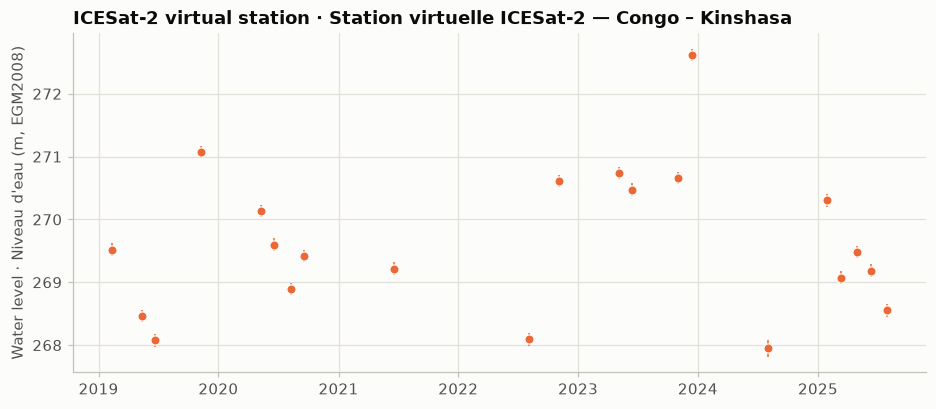

,ICESat-2
observations,21
first · première,2019-02-10
last · dernière,2025-07-29
per year · par an,3.2
median gap (days) · écart médian (jours),70.1
longest gap (days) · plus long écart (jours),412.7


In [16]:
fig, ax = plt.subplots()
ax.errorbar(vs_ice.time, vs_ice.wse_m, yerr=vs_ice.wse_u_m, color=COL["ICESat-2"], elinewidth=1,
            capsize=0, **dots(COL["ICESat-2"]))
ax.set_ylabel(LEVEL_LABEL)
ax.set_title(f"ICESat-2 virtual station · Station virtuelle ICESat-2 — {SITE['short']}")
plt.show()

def sampling_summary(times):
    """How often is the river observed? · À quelle fréquence la rivière est-elle observée ?"""
    t = pd.Series(pd.to_datetime(times)).sort_values()
    gaps = t.diff().dt.total_seconds() / 86400
    years = (t.max() - t.min()).days / 365.25
    return pd.Series({"observations": len(t), "first · première": f"{t.min():%Y-%m-%d}",
                      "last · dernière": f"{t.max():%Y-%m-%d}",
                      "per year · par an": round(len(t) / years, 1) if years > 0 else np.nan,
                      "median gap (days) · écart médian (jours)": round(gaps.median(), 1),
                      "longest gap (days) · plus long écart (jours)": round(gaps.max(), 1)})

sampling_summary(vs_ice.time).to_frame("ICESat-2")

**English**

💬 You now have a real virtual station. Look at the seasonal cycle: when are the lowest and highest levels? How many observations per year do you get, and is that enough for the questions your agency needs to answer?

> **Français**
>
> 💬 Vous avez maintenant une vraie station virtuelle. Regardez le cycle saisonnier : quand surviennent les niveaux les plus bas et les plus hauts ? Combien d'observations par an obtenez-vous, et est-ce suffisant pour les questions auxquelles votre service doit répondre ?

## Step 4 — Add SWOT · Étape 4 — Ajouter SWOT

**English**

SWOT gives, for each pass, the **average water-surface elevation of the whole reach** (`wse`, m above EGM2008) with its uncertainty (`wse_u`). We download the full record for our reach and its two neighbours from **Hydrocron** — no login needed.

SWOT data come with quality flags. The most useful are:

| Field | Meaning | We keep |
|---|---|---|
| `reach_q` | summary quality: 0 good, 1 suspect, 2 degraded, 3 bad | ≤ 1 |
| `xovr_cal_q` | quality of the cross-over calibration: 0 good, 1 suspect, 2 bad | ≤ 1 |
| `reach_q_b` | bit flags explaining `reach_q` (e.g. 128 bright land, 8192 far from nadir, 8388608 height outlier) | for inspection |
| `dark_frac` | share of the reach that looked "dark" (calm water returns little radar signal) | for inspection |
| `time_str` = `no_data` | the reach was in a swath but not measured | removed |

⚠️ With the current SWOT version almost **no reach ever has `reach_q = 0`**, because the summary flag is set very cautiously. Keeping "suspect" (≤ 1) data is the usual practice; you must then check the data yourself — which is what the next cells do.

> **Français**
>
> Pour chaque passage, SWOT fournit l'**altitude moyenne de la surface de l'eau sur tout le tronçon** (`wse`, m au-dessus d'EGM2008) avec son incertitude (`wse_u`). Nous téléchargeons tout l'enregistrement de notre tronçon et de ses deux voisins depuis **Hydrocron** — sans identifiant.
>
> Les données SWOT sont accompagnées d'indicateurs de qualité. Les plus utiles sont :
>
> | Champ | Signification | Nous gardons |
> |---|---|---|
> | `reach_q` | qualité globale : 0 bon, 1 douteux, 2 dégradé, 3 mauvais | ≤ 1 |
> | `xovr_cal_q` | qualité de l'étalonnage par points de croisement : 0 bon, 1 douteux, 2 mauvais | ≤ 1 |
> | `reach_q_b` | bits expliquant `reach_q` (ex. 128 terre brillante, 8192 loin du nadir, 8388608 hauteur aberrante) | pour inspection |
> | `dark_frac` | part du tronçon apparue « sombre » (l'eau calme renvoie peu de signal radar) | pour inspection |
> | `time_str` = `no_data` | le tronçon était dans la fauchée mais n'a pas été mesuré | retiré |
>
> ⚠️ Avec la version actuelle de SWOT, presque **aucun tronçon n'a jamais `reach_q = 0`**, car l'indicateur global est fixé de façon très prudente. Garder les données « douteuses » (≤ 1) est la pratique habituelle ; il faut alors les vérifier soi-même — ce que font les cellules suivantes.

In [17]:
SWOT_FIELDS = ["reach_id", "time_str", "cycle_id", "pass_id", "wse", "wse_u", "wse_r_u", "width", "slope",
               "reach_q", "reach_q_b", "dark_frac", "xovr_cal_q", "ice_clim_f", "partial_f", "n_good_nod",
               "obs_frac_n", "xtrk_dist", "p_lat", "p_lon", "p_width", "river_name", "crid"]

def hydrocron_reach(reach_id, start="2023-07-01", end=None, refresh=REFRESH):
    """SWOT time series for one river reach (Hydrocron, no login).
    Série temporelle SWOT d'un tronçon (Hydrocron, sans identifiant)."""
    f = CACHE / f"swot_reach_{reach_id}.csv"
    if f.exists() and not refresh:
        return pd.read_csv(f, dtype={"reach_id": str, "cycle_id": str, "pass_id": str})
    params = dict(feature="Reach", feature_id=reach_id, output="csv", fields=",".join(SWOT_FIELDS),
                  start_time=f"{start}T00:00:00Z", end_time=f"{end or today()}T23:59:59Z")
    r = http_get(HYDROCRON, params)
    if r.status_code == 400:      # Hydrocron answers 400 when there is no data · 400 = pas de données
        print(f"No SWOT data for reach · Pas de données SWOT pour le tronçon {reach_id}: {r.json().get('error', '')}")
        return pd.DataFrame(columns=SWOT_FIELDS)
    r.raise_for_status()
    df = pd.read_csv(io.StringIO(r.json()["results"]["csv"]), dtype={"reach_id": str, "cycle_id": str, "pass_id": str})
    df.to_csv(f, index=False)
    log_download(f.name, r.url)
    return df

def clean_swot(df, h_range=None, max_reach_q=1, max_xovr_q=1):
    """Label each SWOT observation as kept or removed (with the reason).
    Étiqueter chaque observation SWOT comme gardée ou retirée (avec la raison)."""
    s = df.copy().reset_index(drop=True)
    s["reason"] = "kept"
    nodata = (s.time_str == "no_data") | (s.wse < -1e10)
    s.loc[nodata, "reason"] = "0 not observed"
    s["time"] = utc_naive(s.time_str.where(~nodata))
    s.loc[~nodata & s.duplicated(subset=["time_str"]), "reason"] = "0 duplicate"
    lo, hi = h_range or (-np.inf, np.inf)
    k = s.reason == "kept"
    s.loc[k & ((s.wse < lo) | (s.wse > hi)), "reason"] = "1 impossible level"
    k = s.reason == "kept"
    s.loc[k & (s.reach_q > max_reach_q), "reason"] = f"2 reach_q > {max_reach_q}"
    k = s.reason == "kept"
    s.loc[k & (s.xovr_cal_q > max_xovr_q), "reason"] = f"3 xovr_cal_q > {max_xovr_q}"
    return s

swot = {}
for rid in [SITE["swot_reach"], SITE["swot_up"], SITE["swot_down"]]:
    swot[rid] = clean_swot(hydrocron_reach(rid), h_range=SITE["h_range"])

main = swot[SITE["swot_reach"]]
print(f"Reach · Tronçon {SITE['swot_reach']} ({main.river_name.iloc[0]}), "
      f"processing versions · versions de traitement (crid): {sorted(main.crid.dropna().unique())}")
main.reason.value_counts().rename("observations").to_frame()

Reach · Tronçon 13217000081 (Congo), processing versions · versions de traitement (crid): ['PGD0', 'PID0']


,observations
reason,
kept,62
2 reach_q > 1,46


## A check that needs no statistics: water does not flow uphill · Un contrôle sans statistique : l'eau ne remonte pas la pente

**English**

SWOT measures neighbouring reaches **at the same moment** during a pass. The water level of our reach must therefore be **lower than the reach upstream** and **higher than the reach downstream** (allowing a small tolerance for measurement error). When this is not true, at least one of the measurements is wrong.

⚠️ Do not remove SWOT values just because they are far from the series average. On a flashy river, real floods look exactly like "outliers". The upstream/downstream check is safer, because it uses hydraulics instead of statistics.

> **Français**
>
> SWOT mesure les tronçons voisins **au même moment** lors d'un passage. Le niveau de notre tronçon doit donc être **plus bas que celui du tronçon amont** et **plus haut que celui du tronçon aval** (avec une petite tolérance pour l'erreur de mesure). Si ce n'est pas le cas, au moins une des mesures est fausse.
>
> ⚠️ Ne retirez pas des valeurs SWOT simplement parce qu'elles sont loin de la moyenne de la série. Sur une rivière à crues rapides, les vraies crues ressemblent exactement à des « valeurs aberrantes ». Le contrôle amont/aval est plus sûr, car il s'appuie sur l'hydraulique plutôt que sur la statistique.

In [18]:
def hydraulic_check(main, up=None, down=None, tol_m=0.3):
    """Flag passes where the reach is higher than the reach upstream, or lower than the reach downstream.
    Signaler les passages où le tronçon est plus haut que l'amont, ou plus bas que l'aval."""
    m = main.copy()
    key = ["cycle_id", "pass_id"]
    for nb, sign, label in [(up, 1, "4 higher than upstream"), (down, -1, "4 lower than downstream")]:
        if nb is None or nb.empty:
            continue
        nbk = nb[nb.reason == "kept"][key + ["wse"]].drop_duplicates(key).rename(columns={"wse": "wse_nb"})
        j = m[key].merge(nbk, on=key, how="left")
        bad = (m.reason == "kept").to_numpy() & (sign * (m.wse.to_numpy() - j.wse_nb.to_numpy()) > tol_m)
        m.loc[bad, "reason"] = label
    return m

main = hydraulic_check(swot[SITE["swot_reach"]], swot[SITE["swot_up"]], swot[SITE["swot_down"]])
swot_ok = main[main.reason == "kept"].sort_values("time").reset_index(drop=True)
main.reason.value_counts().rename("observations").to_frame()

,observations
reason,
kept,62
2 reach_q > 1,46


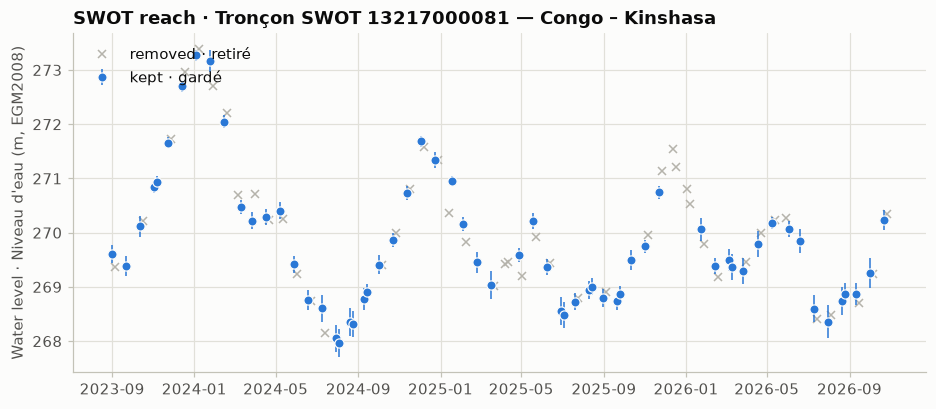

,SWOT
observations,62
first · première,2023-08-31
last · dernière,2026-10-21
per year · par an,19.7
median gap (days) · écart médian (jours),20.9
longest gap (days) · plus long écart (jours),62.6


In [19]:
def plot_swot(main, title):
    obs = main[~main.reason.str.startswith("0")]
    rem, kep = obs[obs.reason != "kept"], obs[obs.reason == "kept"]
    fig, ax = plt.subplots()
    ax.plot(rem.time, rem.wse, marker="x", ms=5, ls="none", color=COL["removed"], label="removed · retiré")
    ax.errorbar(kep.time, kep.wse, yerr=kep.wse_u, color=COL["SWOT"], elinewidth=1, capsize=0,
                **dots(COL["SWOT"]), label="kept · gardé")
    ax.set_ylabel(LEVEL_LABEL); ax.legend(loc="upper left"); ax.set_title(title)
    plt.show()

plot_swot(main, f"SWOT reach · Tronçon SWOT {SITE['swot_reach']} — {SITE['short']}")
sampling_summary(swot_ok.time).to_frame("SWOT")

## Step 5 — Combine the two satellites · Étape 5 — Combiner les deux satellites

**English**

ICESat-2 and SWOT measure the same river with different instruments, at slightly different places, with different processing. Their levels can differ by a near-constant amount — an **inter-mission bias**. We estimate it from the passes where both satellites saw the river **within 3 days** of each other, and shift ICESat-2 onto SWOT's reference (the SWOT reach average). Then we merge the two into one series.

> **Français**
>
> ICESat-2 et SWOT mesurent la même rivière avec des instruments différents, à des endroits légèrement différents, avec des traitements différents. Leurs niveaux peuvent différer d'une valeur presque constante — un **biais entre missions**. Nous l'estimons à partir des passages où les deux satellites ont vu la rivière **à moins de 3 jours** d'intervalle, et nous ramenons ICESat-2 sur la référence de SWOT (la moyenne du tronçon SWOT). Puis nous fusionnons les deux en une seule série.

In [20]:
def intermission_pairs(vs_ice, swot_ok, max_days=3):
    """ICESat-2 and SWOT levels measured within max_days of each other.
    Niveaux ICESat-2 et SWOT mesurés à moins de max_days d'intervalle."""
    a = vs_ice[["time", "wse_m"]].sort_values("time")
    b = swot_ok[["time", "wse"]].rename(columns={"time": "time_swot", "wse": "wse_swot"}).sort_values("time_swot")
    p = pd.merge_asof(a, b, left_on="time", right_on="time_swot", direction="nearest",
                      tolerance=pd.Timedelta(days=max_days)).dropna(subset=["wse_swot"])
    p["days_apart"] = ((p.time - p.time_swot).dt.total_seconds() / 86400).round(1)
    p["difference_m"] = p.wse_m - p.wse_swot
    return p

def combine_levels(vs_ice, swot_ok, offset_m):
    """One table of levels from both satellites, on SWOT's reference · Une table commune, référence SWOT"""
    a = vs_ice.assign(wse_m=vs_ice.wse_m - offset_m)[["time", "wse_m", "wse_u_m", "source"]]
    b = swot_ok.assign(source="SWOT").rename(columns={"wse": "wse_m", "wse_u": "wse_u_m"})[["time", "wse_m", "wse_u_m", "source"]]
    return pd.concat([a, b]).sort_values("time").reset_index(drop=True)

pairs = intermission_pairs(vs_ice, swot_ok)
OFFSET = pairs.difference_m.median() if len(pairs) >= 3 else 0.0
print(f"{len(pairs)} near-simultaneous pairs · paires quasi simultanées ; "
      f"ICESat-2 − SWOT = {OFFSET:+.2f} m (median · médiane)")
if len(pairs) < 3:
    print("⚠️ Fewer than 3 pairs: no offset applied · Moins de 3 paires : aucun décalage appliqué")
vs = combine_levels(vs_ice, swot_ok, OFFSET)
pairs.round(3)

5 near-simultaneous pairs · paires quasi simultanées ; ICESat-2 − SWOT = -0.11 m (median · médiane)


,time,wse_m,time_swot,wse_swot,days_apart,difference_m
13,2023-11-01 22:28:43.847729920,270.661,2023-11-02 00:54:25,270.845,-0.1,-0.184
14,2023-12-13 08:29:03.856563712,272.618,2023-12-13 18:24:34,272.701,-0.4,-0.083
15,2024-07-31 09:27:17.752075264,267.953,2024-07-30 06:40:27,268.050,1.1,-0.098
18,2025-04-29 20:26:08.591902720,269.481,2025-04-27 12:26:29,269.591,2.3,-0.109
19,2025-06-10 06:26:20.786686208,269.182,2025-06-08 05:56:39,269.366,2.0,-0.184


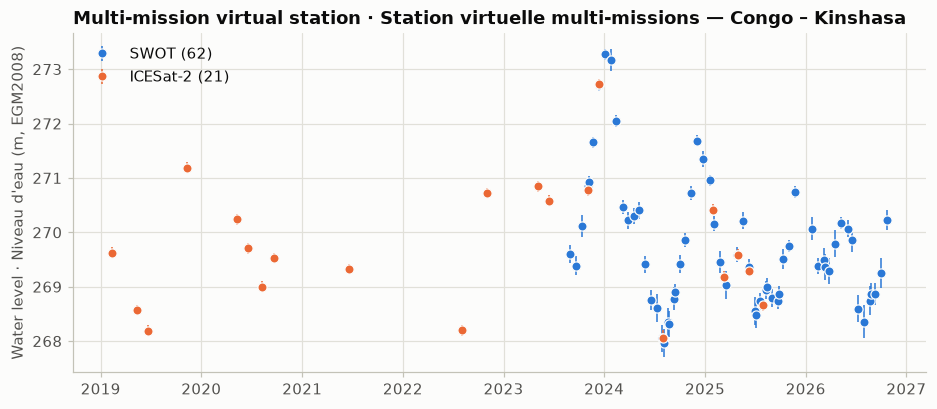

In [21]:
def plot_levels(vs, title):
    fig, ax = plt.subplots()
    for src in ["SWOT", "ICESat-2"]:
        d = vs[vs.source == src]
        ax.errorbar(d.time, d.wse_m, yerr=d.wse_u_m, color=COL[src], elinewidth=1, capsize=0,
                    **dots(COL[src]), label=f"{src} ({len(d)})")
    ax.set_ylabel(LEVEL_LABEL); ax.legend(loc="upper left"); ax.set_title(title)
    plt.show()

plot_levels(vs, f"Multi-mission virtual station · Station virtuelle multi-missions — {SITE['short']}")

## Optional: longer records from DAHITI · Facultatif : séries plus longues avec DAHITI

**English**

**DAHITI** (TU Munich) publishes radar virtual stations that go back to the 1990s–2000s. It needs a free account and API key: register at https://dahiti.dgfi.tum.de, request an API key in your profile, then set it before starting Jupyter (`export DAHITI_API_KEY=...`) or paste it below. Hydroweb.next (https://hydroweb.next.theia-land.fr) offers similar records.

⚠️ These stations are usually at a different place on the river, so compare their **changes** in level rather than their absolute values. *This cell was written from DAHITI's documentation and has not been tested with a key.*

> **Français**
>
> **DAHITI** (TU Munich) publie des stations virtuelles radar qui remontent aux années 1990–2000. Il faut un compte gratuit et une clé API : inscrivez-vous sur https://dahiti.dgfi.tum.de, demandez une clé API dans votre profil, puis définissez-la avant de lancer Jupyter (`export DAHITI_API_KEY=...`) ou collez-la ci-dessous. Hydroweb.next (https://hydroweb.next.theia-land.fr) propose des séries similaires.
>
> ⚠️ Ces stations sont en général situées ailleurs sur la rivière : comparez leurs **variations** de niveau plutôt que leurs valeurs absolues. *Cette cellule a été écrite à partir de la documentation de DAHITI et n'a pas été testée avec une clé.*

In [22]:
DAHITI_API_KEY = os.environ.get("DAHITI_API_KEY", "")   # ✏️ or paste your key · ou collez votre clé

def dahiti_levels(dahiti_id, api_key=DAHITI_API_KEY, refresh=REFRESH):
    """DAHITI water-level series (free API key needed) · Série DAHITI (clé API gratuite nécessaire)"""
    f = CACHE / f"dahiti_{dahiti_id}.csv"
    if f.exists() and not refresh:
        return pd.read_csv(f, parse_dates=["time"])
    if not api_key:
        return None
    r = requests.post("https://dahiti.dgfi.tum.de/api/v2/download-water-level/",
                      json=dict(api_key=api_key, dahiti_id=dahiti_id, format="json"), timeout=120)
    if r.status_code != 200:
        print(f"DAHITI {dahiti_id}: HTTP {r.status_code} — {r.text[:200]}")
        return None
    df = pd.DataFrame(r.json()["data"]).rename(columns={"date": "time", "wse": "wse_m", "wse_u": "wse_u_m"})
    df["time"] = utc_naive(df.time)
    df["source"] = f"DAHITI {dahiti_id}"
    df.to_csv(f, index=False)
    log_download(f.name, f"DAHITI API v2 download-water-level {dahiti_id}")
    return df

dahiti = {i: dahiti_levels(i) for i in SITE.get("dahiti_ids", [])}
dahiti = {i: d for i, d in dahiti.items() if d is not None and len(d)}
if not dahiti:
    print("No DAHITI key or data — skipping this optional step · Pas de clé ou de données DAHITI — étape facultative ignorée")
else:
    fig, ax = plt.subplots()
    for i, d in dahiti.items():
        ax.plot(d.time, d.wse_m - d.wse_m.median(), marker="o", ms=3, lw=0.6, color=COL["muted"], label=f"DAHITI {i}")
    ax.plot(vs.time, vs.wse_m - vs.wse_m.median(), **dots(COL["SWOT"], ms=4), label="this notebook · ce notebook")
    ax.set_ylabel("Level minus median · Niveau moins la médiane (m)"); ax.legend(); plt.show()

No DAHITI key or data — skipping this optional step · Pas de clé ou de données DAHITI — étape facultative ignorée


## Step 6 — Compare with a ground gauge (optional) · Étape 6 — Comparer avec une station au sol (facultatif)

**English**

If your agency has gauge readings for the same stretch of river, this is the most important check of all. Save them as a CSV file in the `data/` folder, named as in `gauge_file` (e.g. `data/gauge_congo_kinshasa.csv`), with these columns (one row per day; leave a cell empty if a value is missing):

```
date,stage_m,discharge_m3s
2024-01-03,6.12,61200
```

The cell below finds the **datum offset** between the gauge zero and EGM2008 (the median difference on days when both exist), puts the gauge on the satellite datum, and measures the agreement.

> **Français**
>
> Si votre service dispose de lectures d'échelle sur le même tronçon de rivière, c'est le contrôle le plus important de tous. Enregistrez-les dans un fichier CSV du dossier `data/`, nommé comme dans `gauge_file` (par ex. `data/gauge_congo_kinshasa.csv`), avec ces colonnes (une ligne par jour ; laissez une case vide si une valeur manque) :
>
> ```
> date,stage_m,discharge_m3s
> 2024-01-03,6.12,61200
> ```
>
> La cellule ci-dessous trouve le **décalage de référence** entre le zéro de l'échelle et EGM2008 (la différence médiane les jours où les deux existent), ramène la station sur la référence satellitaire, et mesure l'accord.

In [23]:
def load_gauge(path):
    """Read an agency gauge file (date, stage_m, discharge_m3s) · Lire un fichier de station"""
    g = pd.read_csv(path)
    g["date"] = utc_naive(g["date"]).dt.normalize()
    for c in ["stage_m", "discharge_m3s"]:
        g[c] = pd.to_numeric(g.get(c), errors="coerce")
    return g.groupby("date")[["stage_m", "discharge_m3s"]].mean()

def skill(obs, sim):
    """Agreement statistics · Statistiques d'accord (r, NSE, KGE, RMSE, PBIAS)"""
    obs, sim = np.asarray(obs, float), np.asarray(sim, float)
    r = np.corrcoef(obs, sim)[0, 1]
    nse = 1 - np.sum((sim - obs) ** 2) / np.sum((obs - obs.mean()) ** 2)
    kge = 1 - np.sqrt((r - 1) ** 2 + (sim.std() / obs.std() - 1) ** 2 + (sim.mean() / obs.mean() - 1) ** 2)
    return pd.Series({"n": len(obs), "r": r, "NSE": nse, "KGE": kge,
                      "RMSE": np.sqrt(np.mean((sim - obs) ** 2)), "PBIAS %": 100 * np.sum(sim - obs) / np.sum(obs)})

gauge = load_gauge(SITE["gauge_file"]) if Path(SITE["gauge_file"]).exists() else None
if gauge is None:
    print(f"No gauge file found · Aucun fichier de station trouvé : {SITE['gauge_file']}\n"
          "→ skipping the gauge comparison · comparaison avec la station ignorée")
else:
    m = vs.assign(date=vs.time.dt.normalize()).join(gauge, on="date").dropna(subset=["stage_m"])
    datum = (m.wse_m - m.stage_m).median()
    print(f"{len(m)} matching days · jours communs ; gauge zero ≈ {datum:.2f} m EGM2008")
    display(m.groupby("source").apply(lambda d: skill(d.stage_m + datum, d.wse_m)).round(3))
    fig, ax = plt.subplots()
    ax.plot(gauge.index, gauge.stage_m + datum, color=COL["Q"], lw=1, label="gauge · station")
    for src in ["SWOT", "ICESat-2"]:
        d = vs[vs.source == src]
        ax.plot(d.time, d.wse_m, **dots(COL[src]), label=src)
    ax.set_xlim(vs.time.min() - pd.Timedelta(days=30), vs.time.max() + pd.Timedelta(days=30))
    ax.set_ylabel(LEVEL_LABEL); ax.legend(); plt.show()

No gauge file found · Aucun fichier de station trouvé : data/gauge_congo_kinshasa.csv
→ skipping the gauge comparison · comparaison avec la station ignorée


## Step 7 — From level to discharge: the rating curve · Étape 7 — Du niveau au débit : la courbe de tarage

**English**

A gauge becomes a **flow** gauge once we know the stage–discharge relation. For a stable river section it usually follows a power law:

> **Q = a · (h − h₀)ᵇ**

- `h₀` is the water level at which the flow would stop (here in m EGM2008, so it is *not* the gauge zero);
- `b` describes the shape of the control: typically **about 1.3–2.5** for natural channels (≈ 1.67 for a wide channel following Manning's equation);
- `a` scales the curve.

To fit it we need **discharge values on the days the satellite measured the level**. In order of preference:
1. **your agency's discharge records** (from gauging and an existing rating) — best;
2. historical observed discharge, e.g. from **GRDC** — good, but often does not overlap the satellite years;
3. a **hydrological model**, such as **GEOGloWS** — always available, but it is a model, not a measurement.

Here we use (3) for the Congo, because it is the only discharge that is openly available for the satellite years. Be ready to question it.

> **Français**
>
> Une station devient une station de **débit** dès que l'on connaît la relation hauteur–débit. Pour une section de rivière stable, elle suit en général une loi puissance :
>
> > **Q = a · (h − h₀)ᵇ**
>
> - `h₀` est le niveau d'eau auquel l'écoulement s'arrêterait (ici en m EGM2008, ce n'est donc *pas* le zéro de l'échelle) ;
> - `b` décrit la forme du contrôle hydraulique : en général **environ 1,3 à 2,5** pour les chenaux naturels (≈ 1,67 pour un chenal large suivant la formule de Manning) ;
> - `a` règle l'échelle de la courbe.
>
> Pour l'ajuster, il faut des **débits aux dates où le satellite a mesuré le niveau**. Par ordre de préférence :
> 1. **les débits de votre service** (jaugeages et courbe de tarage existante) — le mieux ;
> 2. des débits observés historiques, par ex. du **GRDC** — bien, mais souvent sans recouvrement avec les années satellitaires ;
> 3. un **modèle hydrologique**, comme **GEOGloWS** — toujours disponible, mais c'est un modèle, pas une mesure.
>
> Ici, nous utilisons (3) pour le Congo, car c'est le seul débit librement disponible pour les années satellitaires. Soyez prêts à le remettre en question.

In [24]:
GEOGLOWS = "https://geoglows.ecmwf.int/api/v2"

def geoglows_daily(river_id, refresh=REFRESH):
    """GEOGloWS v2 retrospective daily discharge (no login) · Débit journalier rétrospectif GEOGloWS v2"""
    f = CACHE / f"geoglows_{river_id}.csv"
    if f.exists() and not refresh:
        q = pd.read_csv(f, index_col=0)
    else:
        r = http_get(f"{GEOGLOWS}/retrospectivedaily/{river_id}", timeout=240)
        r.raise_for_status()
        q = pd.read_csv(io.StringIO(r.text), index_col=0)
        q.to_csv(f)
        log_download(f.name, r.url)
    q = q.iloc[:, 0].rename("Q_m3s")
    q.index = utc_naive(q.index).normalize()
    return q

q_model = geoglows_daily(SITE["geoglows_id"]) if SITE["geoglows_id"] else None
if q_model is not None:
    print(f"GEOGloWS {SITE['geoglows_id']}: {q_model.index.min():%Y-%m-%d} → {q_model.index.max():%Y-%m-%d}\n")

def geoglows_auto_lookup(lat, lon, refresh=REFRESH):
    """Ask GEOGloWS for the river nearest a point, and that river's mean flow (cached).
    Demander à GEOGloWS la rivière la plus proche d'un point, et son débit moyen (mis en cache)."""
    f = CACHE / f"geoglows_lookup_{lat:.3f}_{lon:.3f}.json"
    if f.exists() and not refresh:
        return json.loads(f.read_text())
    rid = http_get(f"{GEOGLOWS}/getriverid", dict(lat=lat, lon=lon), timeout=60, tries=1).json()["river_id"]
    r = http_get(f"{GEOGLOWS}/retrospectivemonthly/{rid}", timeout=60, tries=1)
    info = {"river_id": rid, "mean_m3s": float(pd.read_csv(io.StringIO(r.text), index_col=0).iloc[:, 0].mean())}
    f.write_text(json.dumps(info))
    log_download(f.name, r.url)
    return info

# ⚠️ Looking up the river ID automatically can pick the wrong river · La recherche automatique peut se tromper de rivière
if q_model is not None:
    try:
        auto = geoglows_auto_lookup(SITE["lat"], SITE["lon"])
        print(f"{'automatic lookup · recherche automatique':42s} river_id {auto['river_id']}: "
              f"mean flow · débit moyen {auto['mean_m3s']:>10,.1f} m³/s")
    except Exception as e:
        print("Automatic lookup not available (offline?) · Recherche automatique indisponible (hors ligne ?) :",
              e.__class__.__name__)
    print(f"{'manual choice · choix manuel':42s} river_id {SITE['geoglows_id']}: "
          f"mean flow · débit moyen {q_model.mean():>10,.1f} m³/s")

GEOGloWS 130798640: 1940-01-01 → 2026-10-16



automatic lookup · recherche automatique   river_id 130594908: mean flow · débit moyen        1.1 m³/s
manual choice · choix manuel               river_id 130798640: mean flow · débit moyen   62,795.2 m³/s


**English**

⚠️ The automatic lookup returns the river reach whose outlet is **nearest** to the point. At Kinshasa it picks a small stream, not the Congo — compare the two mean flows printed above! Always check the river ID on the GEOGloWS map (https://hydroviewer.geoglows.org) and look at the size of the flows before using a model river.

> **Français**
>
> ⚠️ La recherche automatique renvoie le tronçon dont l'exutoire est le **plus proche** du point. À Kinshasa, elle choisit un petit cours d'eau, pas le Congo — comparez les deux débits moyens affichés ci-dessus ! Vérifiez toujours l'identifiant sur la carte GEOGloWS (https://hydroviewer.geoglows.org) et regardez l'ordre de grandeur des débits avant d'utiliser une rivière du modèle.

Reference discharge · Débit de référence : GEOGloWS model · modèle
82 level–discharge pairs · couples hauteur–débit


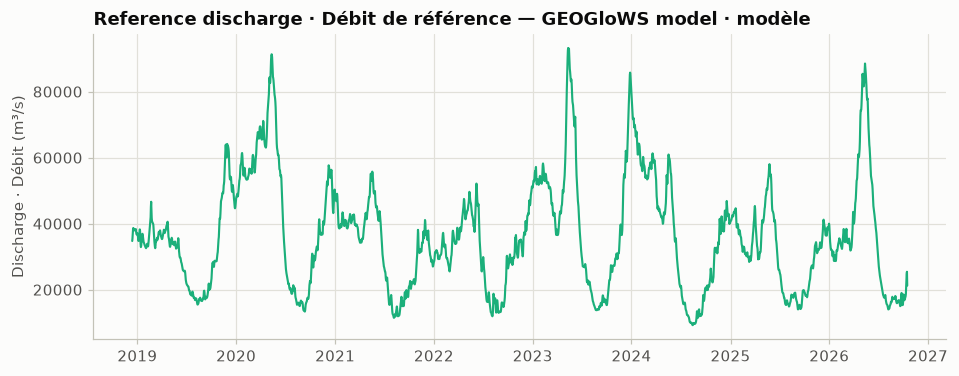

In [25]:
# Reference discharge: the gauge if available, otherwise the model · Débit de référence : la station sinon le modèle
if gauge is not None and gauge.discharge_m3s.notna().sum() > 30:
    q_ref, Q_SOURCE = gauge.discharge_m3s.dropna(), "gauge · station"
elif q_model is not None:
    q_ref, Q_SOURCE = q_model, "GEOGloWS model · modèle"
else:
    q_ref, Q_SOURCE = None, None
print("Reference discharge · Débit de référence :", Q_SOURCE)

if q_ref is not None:
    pairs_q = vs.assign(Q_ref=vs.time.dt.normalize().map(q_ref)).dropna(subset=["Q_ref"]).reset_index(drop=True)
    pairs_q["month"] = pairs_q.time.dt.month
    print(f"{len(pairs_q)} level–discharge pairs · couples hauteur–débit")
    fig, ax = plt.subplots(figsize=(10, 3.6))
    span = q_ref[vs.time.min() - pd.Timedelta(days=60):]
    ax.plot(span.index, span.values, color=COL["Q"], lw=1.4)
    ax.set_ylabel(Q_LABEL)
    ax.set_title(f"Reference discharge · Débit de référence — {Q_SOURCE}")
    plt.show()

In [26]:
def fit_rating(h, q, b_bounds=(1.0, 3.5), h0_search_m=25.0, n_grid=2000):
    """Fit Q = a·(h − h0)^b: try many h0 values, fit a straight line in log space for each, keep the best.
    Ajuster Q = a·(h − h0)^b : essayer de nombreux h0, ajuster une droite en log pour chacun, garder le meilleur."""
    h, q = np.asarray(h, float), np.asarray(q, float)
    y = np.log(q)
    h0 = np.linspace(h.min() - h0_search_m, h.min() - 0.05, n_grid)
    X = np.log(h[None, :] - h0[:, None])
    xm, ym = X.mean(1, keepdims=True), y.mean()
    b = np.clip(((X - xm) * (y - ym)).sum(1) / ((X - xm) ** 2).sum(1), *b_bounds)
    loga = ym - b * xm[:, 0]
    sse = ((loga[:, None] + b[:, None] * X - y) ** 2).sum(1)
    i = int(np.argmin(sse))
    return dict(a=float(np.exp(loga[i])), h0=float(h0[i]), b=float(b[i]), n=len(h),
                edge=bool(i in (0, n_grid - 1)), b_at_bound=bool(b[i] in b_bounds))

def rating_q(h, p):
    """Discharge from level with rating parameters p · Débit à partir du niveau"""
    h = np.asarray(h, float)
    return np.where(h > p["h0"], p["a"] * np.clip(h - p["h0"], 0, None) ** p["b"], 0.0)

def bootstrap_rating(h, q, n_boot=500, seed=1, **kw):
    """Refit the curve on resampled pairs to see how uncertain it is · Réajuster sur des tirages pour l'incertitude"""
    rng = np.random.default_rng(seed)
    h, q = np.asarray(h, float), np.asarray(q, float)
    out = []
    for _ in range(n_boot):
        i = rng.integers(0, len(h), len(h))
        if np.unique(h[i]).size >= 5:
            out.append(fit_rating(h[i], q[i], **kw))
    return pd.DataFrame(out)

def rating_band(h, boot, lo=2.5, hi=97.5):
    Q = np.array([rating_q(h, p) for p in boot.to_dict("records")])
    return np.percentile(Q, lo, axis=0), np.percentile(Q, hi, axis=0)

def describe_rating(p, label):
    msg = f"{label}: Q = {p['a']:.4g} · (h − {p['h0']:.2f})^{p['b']:.2f}   (n = {p['n']})"
    if p["b_at_bound"]:
        msg += "\n   ⚠️ b is at its allowed limit — the data do not support a normal rating shape · b est à sa limite"
    if p["edge"]:
        msg += "\n   ⚠️ h0 is at the edge of the search range · h0 est au bord de la plage de recherche"
    print(msg)

assert q_ref is not None, ("No reference discharge for this site — see Part C · "
                           "Pas de débit de référence pour ce site — voir la partie C")
rating_all = fit_rating(pairs_q.wse_m, pairs_q.Q_ref)
describe_rating(rating_all, "All pairs · Tous les couples")
skill(pairs_q.Q_ref, rating_q(pairs_q.wse_m, rating_all)).round(3).to_frame("fit · ajustement").T

All pairs · Tous les couples: Q = 1.17e+04 · (h − 267.03)^1.00   (n = 82)
   ⚠️ b is at its allowed limit — the data do not support a normal rating shape · b est à sa limite


,n,r,NSE,KGE,RMSE,PBIAS %
fit · ajustement,82.0,0.699,0.473,0.618,12943.855,-5.318


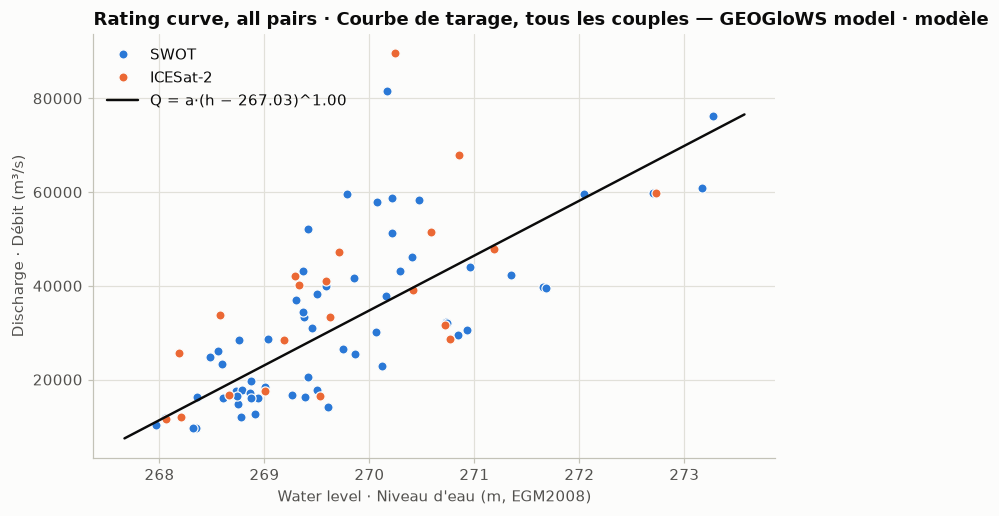

In [27]:
def plot_rating(pairs_q, p, boot=None, title=""):
    fig, ax = plt.subplots(figsize=(8, 5))
    hh = np.linspace(pairs_q.wse_m.min() - 0.3, pairs_q.wse_m.max() + 0.3, 200)
    if boot is not None and len(boot):
        lo, hi = rating_band(hh, boot)
        ax.fill_between(hh, lo, hi, color=COL["ink2"], alpha=0.12, lw=0, label="95% band · bande à 95 %")
    for src in ["SWOT", "ICESat-2"]:
        d = pairs_q[pairs_q.source == src]
        ax.plot(d.wse_m, d.Q_ref, **dots(COL[src]), label=src)
    ax.plot(hh, rating_q(hh, p), color=COL["ink"], lw=1.6, label=f"Q = a·(h − {p['h0']:.2f})^{p['b']:.2f}")
    ax.set_xlabel(LEVEL_LABEL); ax.set_ylabel(Q_LABEL); ax.legend(loc="upper left"); ax.set_title(title)
    plt.show()

plot_rating(pairs_q, rating_all, title=f"Rating curve, all pairs · Courbe de tarage, tous les couples — {Q_SOURCE}")

## Is the scatter the river, or the reference discharge? · La dispersion vient-elle de la rivière ou du débit de référence ?

**English**

At Kinshasa the river is controlled by the **rapids just downstream**, a rock control that does not move. The stage–discharge relation should therefore be close to a single clean curve. If the points scatter a lot, the problem is more likely to be in the **reference discharge** than in the river.

A simple test: plot the **residuals** (reference Q compared with the fitted curve) **by month**. Random errors give bars scattered around zero. A **seasonal pattern** means the model gets the seasons wrong.

> **Français**
>
> À Kinshasa, le fleuve est contrôlé par les **rapides juste en aval**, un seuil rocheux qui ne bouge pas. La relation hauteur–débit devrait donc être proche d'une seule courbe bien nette. Si les points sont très dispersés, le problème vient plus probablement du **débit de référence** que de la rivière.
>
> Un test simple : tracer les **résidus** (débit de référence comparé à la courbe ajustée) **par mois**. Des erreurs aléatoires donnent des barres dispersées autour de zéro. Une **structure saisonnière** signifie que le modèle se trompe de saison.

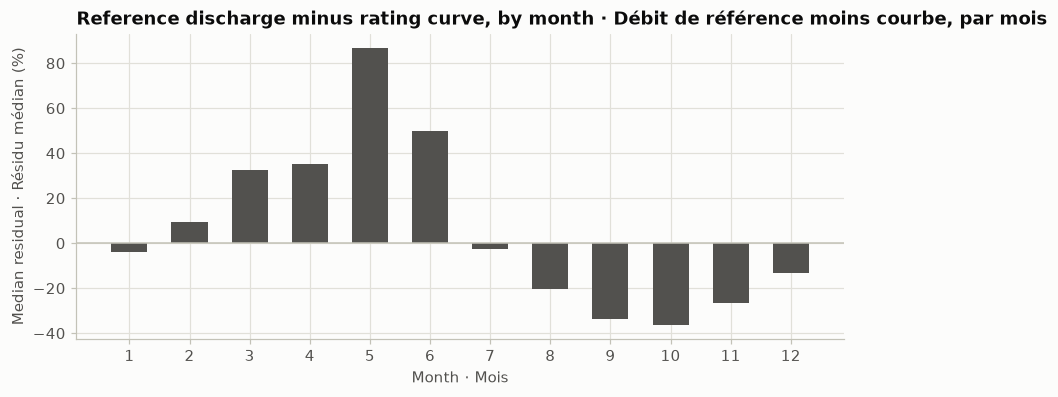

month,1,2,3,4,5,6,7,8,9,10,11,12
median,-4.0,9.0,32.0,35.0,87.0,50.0,-2.0,-20.0,-34.0,-36.0,-27.0,-13.0
count,5.0,5.0,7.0,4.0,7.0,10.0,8.0,11.0,8.0,4.0,9.0,4.0


In [28]:
pairs_q["residual_pct"] = 100 * (pairs_q.Q_ref - rating_q(pairs_q.wse_m, rating_all)) / rating_q(pairs_q.wse_m, rating_all)
by_month = pairs_q.groupby("month").residual_pct.agg(["median", "count"]).reindex(range(1, 13))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(by_month.index, by_month["median"], width=0.6, color=COL["ink2"])
ax.axhline(0, color=COL["axis"], lw=1)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month · Mois"); ax.set_ylabel("Median residual · Résidu médian (%)")
ax.set_title("Reference discharge minus rating curve, by month · Débit de référence moins courbe, par mois")
plt.show()
by_month.round(0).T

**English**

💬 At Kinshasa you should see a clear seasonal pattern: in some months the model discharge is much higher than the satellite levels suggest, in others much lower. Since the rapids control is stable, this tells us about **the model, not the river** — the satellite record is *checking the model*. This is one of the most useful things a virtual gauge can do.

A pragmatic choice is to fit the curve without the months where the model is clearly inconsistent. Write down that choice and the reason for it. ✏️ Change `EXCLUDE_MONTHS` and compare the fits. Remember: the absolute discharge can only be as good as the reference you calibrate against. **Only gauge measurements can confirm it.**

> **Français**
>
> 💬 À Kinshasa, vous devriez voir une structure saisonnière nette : certains mois, le débit du modèle est bien plus élevé que ce que suggèrent les niveaux satellitaires, d'autres mois bien plus faible. Le seuil des rapides étant stable, cela nous renseigne sur **le modèle, pas sur le fleuve** — l'enregistrement satellitaire *contrôle le modèle*. C'est l'un des apports les plus utiles d'une station virtuelle.
>
> Un choix pragmatique consiste à ajuster la courbe sans les mois où le modèle est clairement incohérent. Notez ce choix et sa justification. ✏️ Modifiez `EXCLUDE_MONTHS` et comparez les ajustements. Rappelez-vous : le débit absolu ne peut pas être meilleur que la référence utilisée pour l'étalonnage. **Seuls des jaugeages peuvent le confirmer.**

In [29]:
EXCLUDE_MONTHS = [3, 4, 5, 6] if Q_SOURCE.startswith("GEOGloWS") and SITE_KEY == "congo_kinshasa" else []   # ✏️
use = pairs_q[~pairs_q.month.isin(EXCLUDE_MONTHS)]
rating = fit_rating(use.wse_m, use.Q_ref)
boot = bootstrap_rating(use.wse_m, use.Q_ref)
describe_rating(rating_all, "All months · Tous les mois")
describe_rating(rating, f"Without months · Sans les mois {EXCLUDE_MONTHS}")
print(f"b, 95% range · intervalle à 95 % : {boot.b.quantile(0.025):.2f} – {boot.b.quantile(0.975):.2f}")
pd.DataFrame({"all months · tous les mois": skill(pairs_q.Q_ref, rating_q(pairs_q.wse_m, rating_all)),
              "fit months only · mois ajustés": skill(use.Q_ref, rating_q(use.wse_m, rating))}).T.round(3)

All months · Tous les mois: Q = 1.17e+04 · (h − 267.03)^1.00   (n = 82)
   ⚠️ b is at its allowed limit — the data do not support a normal rating shape · b est à sa limite
Without months · Sans les mois [3, 4, 5, 6]: Q = 257.7 · (h − 263.22)^2.42   (n = 54)
b, 95% range · intervalle à 95 % : 1.19 – 3.50


,n,r,NSE,KGE,RMSE,PBIAS %
all months · tous les mois,82.0,0.699,0.473,0.618,12943.855,-5.318
fit months only · mois ajustés,54.0,0.940,0.882,0.911,5235.059,-1.889


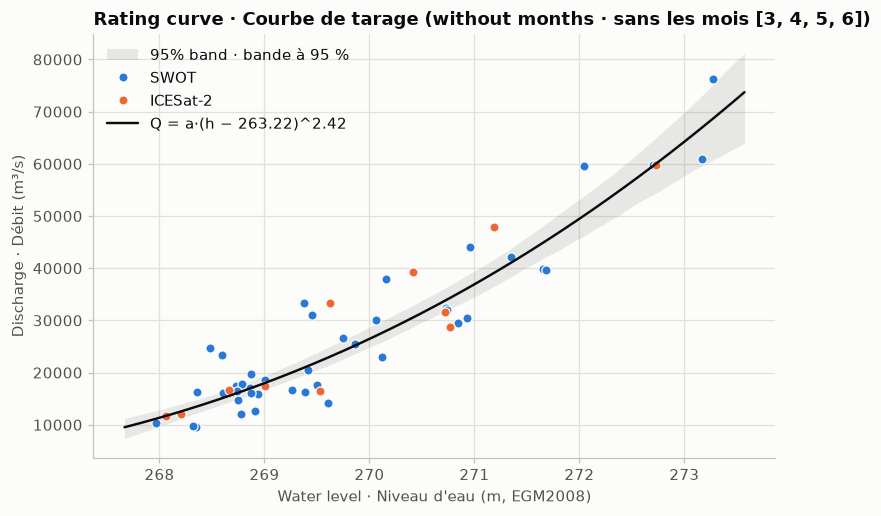

In [30]:
plot_rating(use, rating, boot, title=f"Rating curve · Courbe de tarage (without months · sans les mois {EXCLUDE_MONTHS})")

## Test the curve on years it has not seen · Tester la courbe sur des années non utilisées

**English**

A curve always fits the data it was built from. To judge it fairly, fit it on the earlier years and test it on the later years (**split-sample test**). If the skill drops a lot, the relation is not stable — or there are too few points.

> **Français**
>
> Une courbe s'ajuste toujours bien aux données qui ont servi à la construire. Pour la juger honnêtement, ajustez-la sur les premières années et testez-la sur les dernières (**test par échantillons séparés**). Si la performance chute fortement, la relation n'est pas stable — ou il y a trop peu de points.

In [31]:
SPLIT = pd.Timestamp("2025-01-01")    # ✏️
train, test = use[use.time < SPLIT], use[use.time >= SPLIT]
if len(train) >= 10 and len(test) >= 5:
    r_train = fit_rating(train.wse_m, train.Q_ref)
    describe_rating(r_train, f"Fitted before · Ajusté avant {SPLIT:%Y-%m-%d}")
    display(pd.DataFrame({"train · calage": skill(train.Q_ref, rating_q(train.wse_m, r_train)),
                          "test": skill(test.Q_ref, rating_q(test.wse_m, r_train))}).T.round(3))
else:
    print("Not enough pairs for a split-sample test · Pas assez de couples pour ce test")

Fitted before · Ajusté avant 2025-01-01: Q = 10.75 · (h − 260.96)^3.50   (n = 31)
   ⚠️ b is at its allowed limit — the data do not support a normal rating shape · b est à sa limite


,n,r,NSE,KGE,RMSE,PBIAS %
train · calage,31.0,0.968,0.936,0.944,4636.232,-1.388
test,23.0,0.844,0.329,0.597,7097.968,-22.100


**English**

💬 Compare the calibration and test columns. A large drop in skill, or a large bias (PBIAS) in the test years, means the curve does not transfer well in time. With model discharge this is common; with your own gauging it should be much smaller. Which would you trust for a flood forecast? For an annual water balance?

> **Français**
>
> 💬 Comparez les colonnes calage et test. Une forte baisse de performance, ou un fort biais (PBIAS) sur les années de test, signifie que la courbe se transpose mal dans le temps. C'est fréquent avec un débit modélisé ; avec vos propres jaugeages, l'écart devrait être bien plus faible. À laquelle feriez-vous confiance pour une prévision de crue ? Pour un bilan hydrologique annuel ?

## Another way: matching distributions · Une autre méthode : faire correspondre les distributions

**English**

Sometimes level and discharge records **do not overlap in time** — for example satellite levels since 2018 and gauge discharge that stopped in 2010. Then you can match **quantiles**: the 10 % lowest level is paired with the 10 % lowest discharge, the median with the median, and so on. This assumes the flow regime is the same in both periods. It also ignores timing errors, which can help when a model gets the timing wrong.

> **Français**
>
> Parfois les séries de niveaux et de débits **ne se recouvrent pas dans le temps** — par exemple des niveaux satellitaires depuis 2018 et des débits de station arrêtés en 2010. On peut alors faire correspondre les **quantiles** : le niveau des 10 % les plus bas est associé au débit des 10 % les plus bas, la médiane à la médiane, etc. Cela suppose que le régime d'écoulement est le même sur les deux périodes. Cela ignore aussi les erreurs de calendrier, ce qui peut aider quand un modèle se trompe de dates.

Quantile matching · Correspondance des quantiles: Q = 1.451e+04 · (h − 267.33)^1.04   (n = 19)


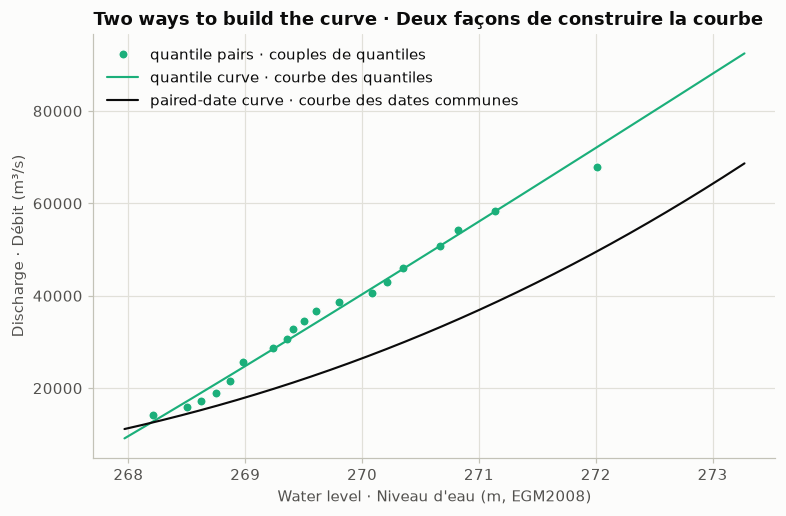

In [32]:
def quantile_pairs(levels, q_series, probs=np.linspace(0.05, 0.95, 19)):
    """Pair level and discharge quantiles · Associer les quantiles de niveau et de débit"""
    return pd.DataFrame({"wse_m": np.quantile(levels, probs), "Q_ref": np.quantile(q_series.dropna(), probs),
                         "source": "quantiles"})

qp = quantile_pairs(vs.wse_m, q_ref[vs.time.min():vs.time.max()])
rating_qm = fit_rating(qp.wse_m, qp.Q_ref)
describe_rating(rating_qm, "Quantile matching · Correspondance des quantiles")
fig, ax = plt.subplots(figsize=(8, 5))
hh = np.linspace(vs.wse_m.min(), vs.wse_m.max(), 200)
ax.plot(qp.wse_m, qp.Q_ref, **dots(COL["Q"]), label="quantile pairs · couples de quantiles")
ax.plot(hh, rating_q(hh, rating_qm), color=COL["Q"], lw=1.4, label="quantile curve · courbe des quantiles")
ax.plot(hh, rating_q(hh, rating), color=COL["ink"], lw=1.4, label="paired-date curve · courbe des dates communes")
ax.set_xlabel(LEVEL_LABEL); ax.set_ylabel(Q_LABEL); ax.legend(loc="upper left")
ax.set_title("Two ways to build the curve · Deux façons de construire la courbe")
plt.show()

## Optional: correct the model with GRDC observations · Facultatif : corriger le modèle avec les observations du GRDC

**English**

The Global Runoff Data Centre holds the long daily discharge record for **Kinshasa (station 1147010)**, up to 2010. It is free, but you must request it yourself at https://portal.grdc.bafg.de (it may not be redistributed). Save the daily file as `data/grdc_1147010.txt`.

The cell below compares GEOGloWS with GRDC over their common years and builds a **quantile mapping**: each model flow is replaced by the observed flow with the same probability of exceedance. The corrected model can then be used as the reference discharge. *This cell was written from the GRDC file format and has not been tested with a real GRDC file.*

> **Français**
>
> Le Global Runoff Data Centre détient la longue série de débits journaliers de **Kinshasa (station 1147010)**, jusqu'en 2010. Elle est gratuite, mais vous devez la demander vous-même sur https://portal.grdc.bafg.de (elle ne peut pas être rediffusée). Enregistrez le fichier journalier sous `data/grdc_1147010.txt`.
>
> La cellule ci-dessous compare GEOGloWS et le GRDC sur leurs années communes et construit une **correction par quantiles** : chaque débit du modèle est remplacé par le débit observé de même probabilité de dépassement. Le modèle corrigé peut alors servir de débit de référence. *Cette cellule a été écrite d'après le format des fichiers GRDC et n'a pas été testée avec un vrai fichier GRDC.*

In [33]:
GRDC_FILE = DATA / "grdc_1147010.txt"     # ✏️
QM_PERIOD = ("1995-01-01", "2010-12-31")  # ✏️ common years used for the correction · années communes

def load_grdc_daily(path):
    """Read a GRDC daily file (header lines start with '#') · Lire un fichier journalier GRDC"""
    df = pd.read_csv(path, sep=";", comment="#", skipinitialspace=True, encoding="latin-1")
    df.columns = [c.strip() for c in df.columns]
    date_col = next(c for c in df.columns if c.upper().startswith("YYYY"))
    val_col = next(c for c in df.columns if c.lower() in ("value", "original", "calculated"))
    q = pd.Series(pd.to_numeric(df[val_col], errors="coerce").to_numpy(), index=utc_naive(df[date_col]), name="Q_m3s")
    return q[q >= 0]

if GRDC_FILE.exists() and q_model is not None:
    q_obs = load_grdc_daily(GRDC_FILE)
    a, b = q_model[QM_PERIOD[0]:QM_PERIOD[1]], q_obs[QM_PERIOD[0]:QM_PERIOD[1]]
    probs = np.linspace(0.005, 0.995, 199)
    qm_model, qm_obs = np.quantile(a.dropna(), probs), np.quantile(b.dropna(), probs)
    q_corrected = pd.Series(np.interp(q_model, qm_model, qm_obs), index=q_model.index, name="Q_m3s")
    print(f"Mean · Moyenne {QM_PERIOD}: GEOGloWS {a.mean():,.0f} m³/s, GRDC {b.mean():,.0f} m³/s")
    print("→ to use it, set · pour l'utiliser : q_ref, Q_SOURCE = q_corrected, 'GEOGloWS corrected · corrigé' "
          "and re-run Step 7 · et relancer l'étape 7")
else:
    print(f"No GRDC file — skipping · Pas de fichier GRDC — étape ignorée ({GRDC_FILE})")

No GRDC file — skipping · Pas de fichier GRDC — étape ignorée (data/grdc_1147010.txt)


## Step 8 — The virtual flow gauge · Étape 8 — La station de débit virtuelle

**English**

We now apply the rating curve to every satellite level, with the 95 % band from the bootstrap. The band shows the **uncertainty of the curve only**: level errors, and any error in the reference discharge, come on top of it.

> **Français**
>
> Nous appliquons maintenant la courbe de tarage à chaque niveau satellitaire, avec la bande à 95 % issue du bootstrap. Cette bande ne montre que **l'incertitude de la courbe** : les erreurs de niveau et celles du débit de référence s'y ajoutent.

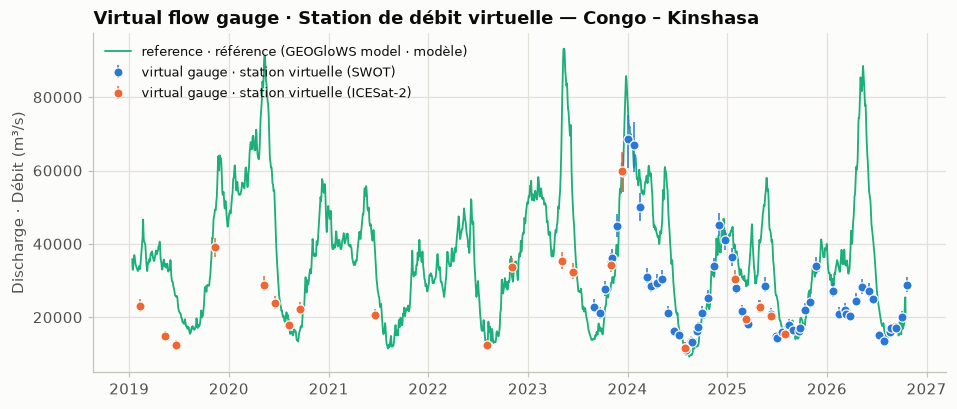

,count,mean,std,min,25%,50%,75%,max
wse_m,83.0,269.7,1.2,268.0,268.9,269.5,270.4,273.3
Q_m3s,83.0,25497.5,12129.4,11154.6,16981.7,22015.0,29895.4,68667.0


In [34]:
lo, hi = rating_band(vs.wse_m, boot)
flow = vs.assign(Q_m3s=rating_q(vs.wse_m, rating), Q_lo=lo, Q_hi=hi)

fig, ax = plt.subplots()
if q_ref is not None:
    span = q_ref[flow.time.min() - pd.Timedelta(days=30):flow.time.max() + pd.Timedelta(days=30)]
    ax.plot(span.index, span.values, color=COL["Q"], lw=1.2, label=f"reference · référence ({Q_SOURCE})")
for src in ["SWOT", "ICESat-2"]:
    d = flow[flow.source == src]
    ax.errorbar(d.time, d.Q_m3s, yerr=[d.Q_m3s - d.Q_lo, d.Q_hi - d.Q_m3s], color=COL[src], elinewidth=1,
                capsize=0, **dots(COL[src]), label=f"virtual gauge · station virtuelle ({src})")
ax.set_ylabel(Q_LABEL); ax.legend(loc="upper left", fontsize=8.5)
ax.set_title(f"Virtual flow gauge · Station de débit virtuelle — {SITE['short']}")
plt.show()
flow[["wse_m", "Q_m3s"]].describe().round(1).T

**English**

💬 For the Congo at Kinshasa, the long-term mean discharge observed since 1903 is about 40,000 m³/s. How does the mean of your virtual gauge (table above) compare? Look back at the monthly residuals: in which months was the model below the satellite-based curve, and how does that affect the low flows? What data would you need to make the absolute discharges trustworthy?

> **Français**
>
> 💬 Pour le Congo à Kinshasa, le débit moyen observé depuis 1903 est d'environ 40 000 m³/s. Comment la moyenne de votre station virtuelle (tableau ci-dessus) se compare-t-elle ? Revenez aux résidus mensuels : quels mois le modèle était-il sous la courbe satellitaire, et quel effet cela a-t-il sur les étiages ? De quelles données auriez-vous besoin pour que les débits absolus soient fiables ?

In [35]:
def export_virtual_gauge(site_key, flow, rating, extra=None):
    """Write the virtual gauge record and its metadata · Écrire l'enregistrement et ses métadonnées"""
    out = flow.assign(date=flow.time.dt.strftime("%Y-%m-%d"), time_utc=flow.time.dt.strftime("%Y-%m-%dT%H:%M:%SZ"))
    cols = ["date", "time_utc", "source", "wse_m", "wse_u_m"] + [c for c in ["Q_m3s", "Q_lo", "Q_hi"] if c in out]
    f = OUT / f"{site_key}_virtual_gauge.csv"
    out[cols].round(3).to_csv(f, index=False)
    meta = {"site": SITES[site_key]["name"], "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
            "height_reference": "EGM2008 geoid (orthometric), metres",
            "level_sources": "SWOT RiverSP Version D reach " + SITES[site_key]["swot_reach"]
                             + " (Hydrocron); ICESat-2 ATL13 v007 (SlideRule)",
            "rating_curve": rating, "notes": extra or {}}
    (OUT / f"{site_key}_virtual_gauge_metadata.json").write_text(json.dumps(meta, indent=1, default=str))
    print("Written · Écrit :", f, "and · et", f.with_name(f.stem + "_metadata.json"))
    return f

export_virtual_gauge(SITE_KEY, flow, rating, extra={
    "reference_discharge": Q_SOURCE, "excluded_months": EXCLUDE_MONTHS,
    "icesat2_minus_swot_offset_m": round(float(OFFSET), 3), "slope_m_per_km": round(float(SLOPE), 4),
    "Q_band": "2.5–97.5 % bootstrap of the rating curve only"})

Written · Écrit : outputs/congo_kinshasa_virtual_gauge.csv and · et outputs/congo_kinshasa_virtual_gauge_metadata.json


PosixPath('outputs/congo_kinshasa_virtual_gauge.csv')

## Part C — The same method on the Rewa, Fiji · Partie C — La même méthode sur la Rewa, aux Fidji

**English**

The Rewa is Fiji's largest river (catchment ≈ 2,900 km²). Its floods come from tropical cyclones and heavy rain and pass in **hours to a few days**, and its lower course near Nausori is **tidal**. It is 100–400 m wide — at the limit of what SWOT is designed for.

First we put every step from Part B into **one function**, so that it can be run on any site in the `SITES` dictionary.

> **Français**
>
> La Rewa est la plus grande rivière des Fidji (bassin ≈ 2 900 km²). Ses crues sont dues aux cyclones tropicaux et aux fortes pluies et passent en **quelques heures à quelques jours**, et son cours inférieur près de Nausori est **soumis à la marée**. Elle fait 100 à 400 m de large — à la limite de ce pour quoi SWOT est conçu.
>
> Nous regroupons d'abord toutes les étapes de la partie B dans **une seule fonction**, pour pouvoir l'appliquer à n'importe quel site du dictionnaire `SITES`.

In [36]:
def build_virtual_station(site_key):
    """Steps 0–5 for one site: mask, ICESat-2, SWOT, checks, combined levels.
    Étapes 0 à 5 pour un site : masque, ICESat-2, SWOT, contrôles, niveaux combinés."""
    site = SITES[site_key]
    line = reach_line(site["swot_reach"])
    geo = channel_mask(line, site["mask_width_m"], site["mask_frac"])
    raw = fetch_atl13(site_key, geo["mask_ll"], site["t0"])
    pts = prepare_atl13(raw, geo, h_range=site["h_range"])
    slopes = estimate_slope(pts)
    slope = slopes.slope_m_per_km.median() if (site["slope_correction"] and len(slopes)) else 0.0
    vs_ice = per_pass_levels(pts, slope, s_ref_km=geo["length_km"] / 2)
    sw = {rid: clean_swot(hydrocron_reach(rid), h_range=site["h_range"])
          for rid in [site["swot_reach"], site.get("swot_up"), site.get("swot_down")] if rid}
    main = hydraulic_check(sw[site["swot_reach"]], sw.get(site.get("swot_up")), sw.get(site.get("swot_down")))
    swot_ok = main[main.reason == "kept"].sort_values("time").reset_index(drop=True)
    pairs = intermission_pairs(vs_ice, swot_ok)
    offset = pairs.difference_m.median() if len(pairs) >= 3 else 0.0
    return dict(site=site, geo=geo, raw=raw, points=pts, slopes=slopes, slope=slope, vs_ice=vs_ice,
                swot=sw, swot_main=main, swot_ok=swot_ok, pairs=pairs, offset=offset,
                vs=combine_levels(vs_ice, swot_ok, offset))

R = build_virtual_station("rewa_fiji")
print(f"ICESat-2 points · points : {len(R['raw']):,}; kept · gardés : {(R['points'].reason == 'kept').sum():,}")
print(f"Slope · Pente : {R['slope'] * 100:.1f} cm/km from · à partir de {len(R['slopes'])} passes")
print(f"ICESat-2 − SWOT = {R['offset']:+.2f} m from · à partir de {len(R['pairs'])} pairs · paires")
pd.concat([R["points"].reason.value_counts().rename("ICESat-2 points"),
           R["swot_main"].reason.value_counts().rename("SWOT observations")], axis=1).fillna(0).astype(int)

ICESat-2 points · points : 1,211; kept · gardés : 875
Slope · Pente : 4.1 cm/km from · à partir de 3 passes
ICESat-2 − SWOT = +0.07 m from · à partir de 3 pairs · paires


,ICESat-2 points,SWOT observations
reason,,
kept,875,82
3 cloudy,304,0
4 outlier in pass,3,0
2 reach_q > 1,0,20
4 higher than upstream,0,6


In [37]:
site_map(R["site"], R["geo"], points=R["raw"])

,pass_id,slope_m_per_km,n_points,span_km
0,2018-12-26_rgt1357,0.031,45,6.025
1,2020-09-25_rgt21,0.041,223,12.167
2,2023-03-22_rgt21,0.052,102,4.022


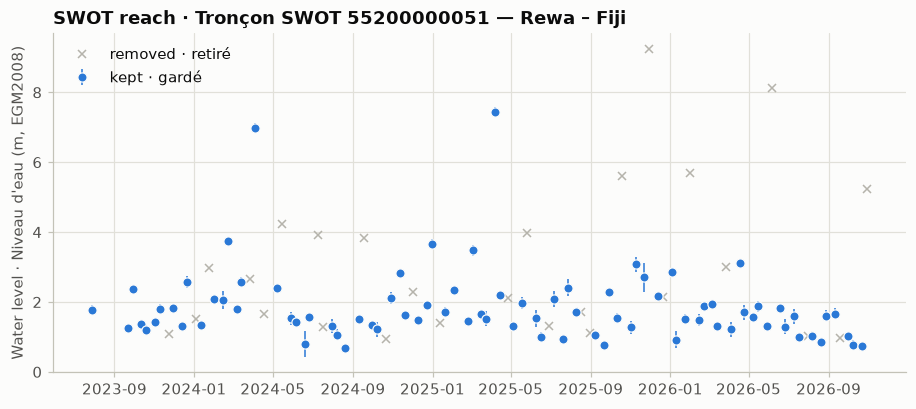

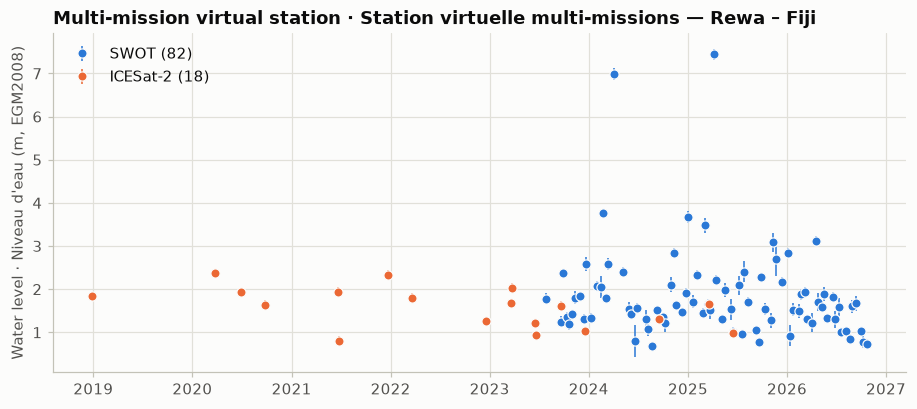

In [38]:
display(R["slopes"].round(3))
plot_swot(R["swot_main"], f"SWOT reach · Tronçon SWOT {R['site']['swot_reach']} — {R['site']['short']}")
plot_levels(R["vs"], f"Multi-mission virtual station · Station virtuelle multi-missions — {R['site']['short']}")

**English**

💬 Look at the slope table: on a tidal river, the water surface can even slope **upstream** while the tide is rising. One median slope is a simplification here. 🧪 Set `slope_correction=False` for `rewa_fiji` in `SITES`, delete `cache/atl13_rewa_fiji.parquet` (or keep it — the slope is computed from it, not downloaded), re-run, and compare.

Look also at the SWOT removals: several high "floods" on this reach were higher than the reach **upstream** at the same moment — impossible, so they were removed. Others survived: are they believable?

> **Français**
>
> 💬 Regardez le tableau des pentes : sur une rivière à marée, la surface de l'eau peut même pencher **vers l'amont** pendant la marée montante. Une seule pente médiane est ici une simplification. 🧪 Mettez `slope_correction=False` pour `rewa_fiji` dans `SITES`, relancez, et comparez (le fichier `cache/atl13_rewa_fiji.parquet` peut être conservé : la pente est calculée à partir de lui, pas téléchargée).
>
> Regardez aussi les retraits SWOT : plusieurs « crues » élevées sur ce tronçon étaient plus hautes que le tronçon **amont** au même moment — impossible, elles ont donc été retirées. D'autres ont été gardées : sont-elles crédibles ?

## Tide or flood? Three reaches of the Rewa · Marée ou crue ? Trois tronçons de la Rewa

**English**

We compare three SWOT reaches from the coast upwards: **Nausori** (tidal), our **main reach**, and the reach **upstream**. Each panel has the same vertical scale.

> **Français**
>
> Nous comparons trois tronçons SWOT de la côte vers l'amont : **Nausori** (soumis à la marée), notre **tronçon principal**, et le tronçon **amont**. Tous les panneaux ont la même échelle verticale.

Nausori (tidal · marée): 40 kept · gardés ; range · amplitude 0.16 – 1.74 m
Main · Principal (55200000051): 82 kept · gardés ; range · amplitude 0.68 – 7.44 m
Upstream · Amont (55200000061): 92 kept · gardés ; range · amplitude 1.72 – 8.02 m


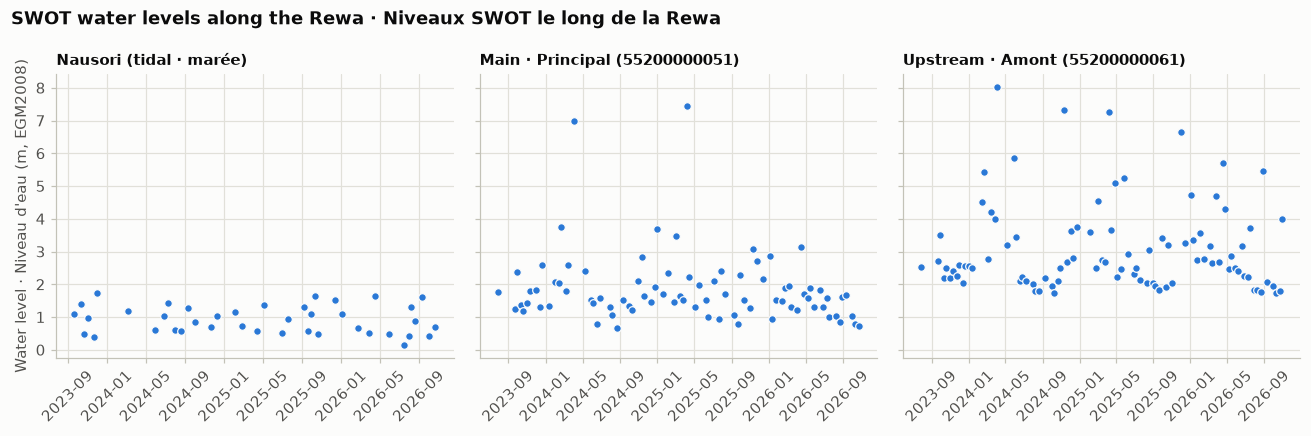

In [39]:
NAUSORI = "55200000031"
rewa_reaches = {
    "Nausori (tidal · marée)": clean_swot(hydrocron_reach(NAUSORI), h_range=SITES["rewa_fiji"]["h_range"]),
    f"Main · Principal ({R['site']['swot_reach']})": R["swot_main"],
    f"Upstream · Amont ({R['site']['swot_up']})": R["swot"][R["site"]["swot_up"]],
}
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, (label, d) in zip(axes, rewa_reaches.items()):
    k = d[d.reason == "kept"]
    ax.plot(k.time, k.wse, **dots(COL["SWOT"], ms=5))
    ax.set_title(label, fontsize=10)
    ax.tick_params(axis="x", labelrotation=45)
    print(f"{label}: {len(k)} kept · gardés ; range · amplitude {k.wse.min():.2f} – {k.wse.max():.2f} m")
axes[0].set_ylabel(LEVEL_LABEL)
fig.suptitle("SWOT water levels along the Rewa · Niveaux SWOT le long de la Rewa", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**English**

💬 At Nausori the level stays in a narrow band and changes from pass to pass with no seasonal pattern: this is mainly the **tide** (SWOT passes at different times of the tidal cycle). Upstream, the floods appear. A rating curve needs a unique relation between level and flow, so **it cannot work where the tide controls the level**. Choose virtual stations above the tidal limit, or use only levels clearly above the tidal range.

> **Français**
>
> 💬 À Nausori, le niveau reste dans une bande étroite et change d'un passage à l'autre sans structure saisonnière : c'est surtout la **marée** (SWOT passe à différents moments du cycle de marée). Plus en amont, les crues apparaissent. Une courbe de tarage suppose une relation unique entre niveau et débit : **elle ne peut pas fonctionner là où la marée commande le niveau**. Choisissez des stations virtuelles au-dessus de la limite de marée, ou n'utilisez que les niveaux nettement supérieurs au marnage.

## How many floods will a satellite catch? · Combien de crues un satellite va-t-il voir ?

**English**

For each possible event length (1, 2, 3, … days) we count, over the whole SWOT period, the share of all such windows that contain **at least one** satellite observation. This is the chance of catching a flood of that duration *at any point during it* — catching the **peak** is much less likely.

> **Français**
>
> Pour chaque durée d'événement possible (1, 2, 3, … jours), nous comptons, sur toute la période SWOT, la part de toutes ces fenêtres qui contiennent **au moins une** observation satellitaire. C'est la probabilité de voir une crue de cette durée *à un moment quelconque* — voir le **pic** est beaucoup moins probable.

In [40]:
def catch_probability(times, start, end, durations=(1, 2, 3, 5, 10, 30)):
    """Share of all D-day windows containing at least one observation · Part des fenêtres de D jours observées"""
    days = pd.date_range(pd.Timestamp(start).normalize(), pd.Timestamp(end).normalize(), freq="D")
    obs = pd.Series(days.isin(pd.to_datetime(pd.Series(times)).dt.normalize()).astype(float), index=days)
    return pd.Series({f"{d} d · j": obs.rolling(d).max().shift(-(d - 1)).dropna().mean() for d in durations})

rows = {}
for label, res in [("Congo – Kinshasa", {"vs": vs}), ("Rewa – Fiji", R)]:
    v = res["vs"]
    start, end = v[v.source == "SWOT"].time.min(), v.time.max()
    rows[f"{label}: SWOT"] = catch_probability(v[v.source == "SWOT"].time, start, end)
    rows[f"{label}: SWOT + ICESat-2"] = catch_probability(v.time, start, end)
(pd.DataFrame(rows).T * 100).round(0).astype(int).astype(str) + " %"

,1 d · j,2 d · j,3 d · j,5 d · j,10 d · j,30 d · j
Congo – Kinshasa: SWOT,5 %,11 %,16 %,26 %,48 %,96 %
Congo – Kinshasa: SWOT + ICESat-2,6 %,12 %,17 %,28 %,50 %,96 %
Rewa – Fiji: SWOT,7 %,14 %,20 %,34 %,62 %,97 %
Rewa – Fiji: SWOT + ICESat-2,7 %,14 %,21 %,35 %,63 %,97 %


**English**

💬 On the Congo, a flood wave lasts months, so every flood is observed many times. On the Rewa, a 1–2 day flood has only a small chance of being seen at all. For flood warning on small rivers, satellite altimetry **complements** ground gauges; it does not replace them. It is most useful for the seasonal regime, low flows, long-term change, and checking models and ratings.

> **Français**
>
> 💬 Sur le Congo, une onde de crue dure des mois : chaque crue est observée de nombreuses fois. Sur la Rewa, une crue de 1 à 2 jours n'a qu'une faible probabilité d'être vue. Pour l'alerte aux crues sur les petites rivières, l'altimétrie satellitaire **complète** les stations au sol ; elle ne les remplace pas. Elle est surtout utile pour le régime saisonnier, les étiages, l'évolution à long terme et le contrôle des modèles et des courbes de tarage.

## Discharge on the Rewa · Le débit de la Rewa

**English**

There is no open discharge record for the Rewa during the satellite years, and Fiji is not in the GEOGloWS model. The rating step therefore needs **your own gauge data** (for example the Rewa at Navolau or Nausori), saved as `data/gauge_rewa_fiji.csv`. If the file is there, the cell below compares the gauge with the satellites and fits the curve with the same functions as in Part B. Otherwise it saves the water-level record only.

Without gauge data you can still use the GloFAS model (free Copernicus account: https://ewds.climate.copernicus.eu) as a reference, with the same caution as for GEOGloWS.

> **Français**
>
> Il n'existe pas de série de débits ouverte pour la Rewa pendant les années satellitaires, et les Fidji ne sont pas couvertes par le modèle GEOGloWS. L'étape de tarage demande donc **vos propres données de station** (par exemple la Rewa à Navolau ou à Nausori), enregistrées sous `data/gauge_rewa_fiji.csv`. Si le fichier est présent, la cellule ci-dessous compare la station aux satellites et ajuste la courbe avec les mêmes fonctions que dans la partie B. Sinon, elle enregistre uniquement les niveaux d'eau.
>
> Sans données de station, vous pouvez quand même utiliser le modèle GloFAS (compte Copernicus gratuit : https://ewds.climate.copernicus.eu) comme référence, avec la même prudence que pour GEOGloWS.

In [41]:
gf = Path(R["site"]["gauge_file"])
if gf.exists():
    g = load_gauge(gf)
    m = R["vs"].assign(date=R["vs"].time.dt.normalize()).join(g, on="date")
    if m.stage_m.notna().sum() >= 3:
        datum = (m.wse_m - m.stage_m).median()
        print(f"Gauge zero · Zéro de l'échelle ≈ {datum:.2f} m EGM2008")
        display(skill(m.dropna(subset=["stage_m"]).stage_m + datum, m.dropna(subset=["stage_m"]).wse_m).round(3).to_frame().T)
    pq = m.dropna(subset=["discharge_m3s"]).rename(columns={"discharge_m3s": "Q_ref"})
    if len(pq) >= 8:
        r_rewa = fit_rating(pq.wse_m, pq.Q_ref)
        b_rewa = bootstrap_rating(pq.wse_m, pq.Q_ref)
        describe_rating(r_rewa, "Rewa")
        plot_rating(pq, r_rewa, b_rewa, title="Rating curve · Courbe de tarage — Rewa")
        lo, hi = rating_band(R["vs"].wse_m, b_rewa)
        export_virtual_gauge("rewa_fiji", R["vs"].assign(Q_m3s=rating_q(R["vs"].wse_m, r_rewa), Q_lo=lo, Q_hi=hi),
                             r_rewa, extra={"reference_discharge": "agency gauge · station du service"})
    else:
        print("Too few discharge values on satellite dates · Trop peu de débits aux dates satellitaires")
else:
    print(f"No gauge file · Pas de fichier de station ({gf}) — exporting water levels only · export des niveaux seulement")
    export_virtual_gauge("rewa_fiji", R["vs"], rating=None,
                         extra={"icesat2_minus_swot_offset_m": round(float(R["offset"]), 3)})

No gauge file · Pas de fichier de station (data/gauge_rewa_fiji.csv) — exporting water levels only · export des niveaux seulement
Written · Écrit : outputs/rewa_fiji_virtual_gauge.csv and · et outputs/rewa_fiji_virtual_gauge_metadata.json


## Part D — Your own river · Partie D — Votre propre rivière

**English**

**Checklist**
1. **Find the SWOT reach.** Fastest: open https://www.swordexplorer.com, zoom to your river, click the reach and copy its **reach ID** (11 digits). Note the IDs of the reaches just upstream and downstream too. Or use `find_swot_reaches()` below (slow: 1–3 minutes).
2. ⚠️ SWOT **Version D** uses **SWORD v17b** reach IDs. Older IDs (SWORD v16) point to different places.
3. Check the reach is wide enough (> 100 m is best) and not tidal or affected by a dam or a confluence just downstream.
4. Fill in a new entry in `SITES` (copy the template below), choose a realistic `h_range`, and run `build_virtual_station()`.
5. Look at **every** figure: the map, the cleaning, the slope, the agreement between missions.
6. For discharge, use your own gauge data whenever possible.

> **Français**
>
> **Liste de contrôle**
> 1. **Trouver le tronçon SWOT.** Le plus rapide : ouvrez https://www.swordexplorer.com, zoomez sur votre rivière, cliquez sur le tronçon et copiez son **identifiant** (11 chiffres). Notez aussi les identifiants des tronçons juste en amont et en aval. Ou utilisez `find_swot_reaches()` ci-dessous (lent : 1 à 3 minutes).
> 2. ⚠️ La **version D** de SWOT utilise les identifiants **SWORD v17b**. Les anciens identifiants (SWORD v16) désignent d'autres endroits.
> 3. Vérifiez que le tronçon est assez large (> 100 m de préférence) et qu'il n'est pas soumis à la marée ni influencé par un barrage ou une confluence juste en aval.
> 4. Ajoutez une entrée dans `SITES` (copiez le modèle ci-dessous), choisissez une plage `h_range` réaliste, et lancez `build_virtual_station()`.
> 5. Regardez **chaque** figure : la carte, le nettoyage, la pente, l'accord entre missions.
> 6. Pour le débit, utilisez vos propres données de station chaque fois que possible.

In [42]:
SWOT_GIS = ("https://gis.earthdata.nasa.gov/portal/rest/services/C3233944997_POCLOUD/"
            "SWOT_L2_HR_RiverSP_reach_vD_Attributes/FeatureServer/1/query")

def find_swot_reaches(lat, lon, radius_m=3000, days=30):
    """SWOT reaches observed near a point in a recent month (NASA Earthdata GIS service — slow, 1–3 min).
    Tronçons SWOT observés près d'un point au cours d'un mois récent (service SIG NASA — lent, 1 à 3 min)."""
    t1 = pd.Timestamp.now(tz="UTC").normalize() - pd.Timedelta(days=10)
    t0 = t1 - pd.Timedelta(days=days)
    params = dict(where="1=1", geometry=f"{lon},{lat}", geometryType="esriGeometryPoint", inSR=4326,
                  distance=radius_m, units="esriSRUnit_Meter", spatialRel="esriSpatialRelIntersects",
                  time=f"{int(t0.timestamp() * 1000)},{int(t1.timestamp() * 1000)}",
                  outFields="reach_id,river_name", returnGeometry="false", f="json")
    r = http_get(SWOT_GIS, params, timeout=300, tries=1)
    feats = r.json().get("features", [])
    ids = pd.DataFrame([f["attributes"] for f in feats]).drop_duplicates("reach_id") if feats else pd.DataFrame()
    rows = []
    for rid in ids.get("reach_id", []):    # describe each reach with Hydrocron · décrire chaque tronçon
        d = hydrocron_reach(rid)
        obs = d[d.time_str != "no_data"]
        if len(d):
            dist = np.hypot((d.p_lat.iloc[0] - lat) * 111, (d.p_lon.iloc[0] - lon) * 111 * np.cos(np.radians(lat)))
            rows.append(dict(reach_id=rid, river=d.river_name.iloc[0], p_lat=d.p_lat.iloc[0], p_lon=d.p_lon.iloc[0],
                             width_m=d.p_width.iloc[0], km_from_point=round(dist, 1), observations=len(obs)))
    return pd.DataFrame(rows).sort_values("km_from_point") if rows else ids

RUN_LOOKUP = False   # ✏️ True to search (slow) · True pour chercher (lent)
if RUN_LOOKUP:
    display(find_swot_reaches(lat=-17.961, lon=178.435))

In [43]:
# ✏️ Template for your river · Modèle pour votre rivière
SITES["my_river"] = dict(
    name="My river at ... · Ma rivière à ...",
    short="My river",
    lat=None, lon=None,                 # e.g. · ex. -4.27, 15.34
    swot_reach=None,                    # 11-digit SWORD v17b reach ID · identifiant à 11 chiffres
    swot_up=None, swot_down=None,       # neighbouring reaches (or None) · tronçons voisins (ou None)
    mask_width_m=None, mask_frac=0.45,  # typical width (m) · largeur typique (m)
    h_range=(None, None),               # plausible levels, m EGM2008 · niveaux plausibles
    slope_correction=True,
    geoglows_id=None,
    gauge_file=DATA / "gauge_my_river.csv",
    dahiti_ids=[],
    t0="2018-10-14",
)

needed = ["lat", "lon", "swot_reach", "mask_width_m"]
if all(SITES["my_river"][k] is not None for k in needed) and None not in SITES["my_river"]["h_range"]:
    MY = build_virtual_station("my_river")
    display(site_map(MY["site"], MY["geo"], points=MY["raw"]))
    plot_levels(MY["vs"], MY["site"]["short"])
    export_virtual_gauge("my_river", MY["vs"], rating=None)
else:
    print("Fill in the template above, then run this cell again · Remplissez le modèle ci-dessus, puis relancez cette cellule")

Fill in the template above, then run this cell again · Remplissez le modèle ci-dessus, puis relancez cette cellule


## Summary · Résumé

**English**

- A satellite altimeter gives water levels relative to the **EGM2008 geoid**; a gauge reads from its own zero. Expect an offset.
- **ICESat-2** (laser, no login via SlideRule) gives precise but sparse levels; **SWOT** (swath, no login via Hydrocron) gives a level for every ~10 km reach, one to several times every 21 days.
- Good virtual stations come from **careful cleaning**: a narrow water mask, cloud and outlier filters, slope correction, and the **upstream/downstream check** for SWOT. Never delete floods as "outliers".
- A rating curve is only as good as the **reference discharge**. Model discharge can be biased by season; the satellite record can reveal this.
- Large, slow rivers (Congo) suit altimetry very well. Small, flashy and tidal rivers (Rewa) are much harder: floods are often missed and tides break the stage–discharge relation.

> **Français**
>
> - Un altimètre satellitaire donne des niveaux par rapport au **géoïde EGM2008** ; une station lit depuis son propre zéro. Attendez-vous à un décalage.
> - **ICESat-2** (laser, sans identifiant via SlideRule) donne des niveaux précis mais rares ; **SWOT** (fauchée, sans identifiant via Hydrocron) donne un niveau pour chaque tronçon de ~10 km, une à plusieurs fois tous les 21 jours.
> - Les bonnes stations virtuelles viennent d'un **nettoyage soigneux** : masque d'eau étroit, filtres nuages et valeurs aberrantes, correction de pente, et **contrôle amont/aval** pour SWOT. Ne supprimez jamais les crues comme « valeurs aberrantes ».
> - Une courbe de tarage ne vaut que ce que vaut le **débit de référence**. Un débit modélisé peut être biaisé selon la saison ; l'enregistrement satellitaire peut le révéler.
> - Les grands fleuves lents (Congo) se prêtent très bien à l'altimétrie. Les petites rivières à crues rapides et à marée (Rewa) sont bien plus difficiles : les crues sont souvent manquées et la marée rompt la relation hauteur–débit.

## Glossary · Glossaire

| English | Français | Meaning · Sens |
|---|---|---|
| altimeter | altimètre | instrument measuring height from the time of a pulse's return · mesure la hauteur à partir du temps de retour d'une impulsion |
| range | distance mesurée (range) | satellite-to-surface distance · distance satellite–surface |
| ellipsoid (WGS84) | ellipsoïde (WGS84) | smooth mathematical shape of the Earth · forme mathématique lisse de la Terre |
| geoid (EGM2008) | géoïde (EGM2008) | surface of mean sea level extended under land · niveau moyen des mers prolongé sous les terres |
| orthometric height | altitude orthométrique | height above the geoid · hauteur au-dessus du géoïde |
| ground track | trace au sol | line on the ground under a nadir altimeter · ligne au sol sous un altimètre au nadir |
| swath | fauchée | wide strip mapped by SWOT · large bande cartographiée par SWOT |
| reach | tronçon | ~10 km section of river in SWORD · section de rivière de ~10 km dans SWORD |
| virtual station | station virtuelle | place where a satellite repeatedly measures a river · lieu où un satellite mesure régulièrement une rivière |
| gauge zero / datum | zéro de l'échelle / référence altimétrique | reference level of a staff gauge · niveau de référence d'une échelle limnimétrique |
| water-surface slope | pente de la ligne d'eau | fall of the water surface per km · descente de la surface de l'eau par km |
| outlier | valeur aberrante | value inconsistent with the rest · valeur incohérente avec les autres |
| median absolute deviation (MAD) | écart absolu médian | robust measure of spread · mesure robuste de dispersion |
| inter-mission bias | biais entre missions | constant difference between two satellites · différence constante entre deux satellites |
| rating curve | courbe de tarage | stage–discharge relation · relation hauteur–débit |
| discharge | débit | volume of water per second (m³/s) · volume d'eau par seconde (m³/s) |
| low flow / flood | étiage / crue | — |
| backwater / tide | remous / marée | downstream effects that break the rating · effets aval qui faussent la courbe |
| quantile mapping | correction par quantiles | matching two distributions · mise en correspondance de deux distributions |

## Further reading · Pour aller plus loin

- Hydrocron (SWOT time series · séries SWOT): https://podaac.github.io/hydrocron/
- SWOT RiverSP product · produit SWOT RiverSP (Version D): https://www.earthdata.nasa.gov/data/catalog/pocloud-swot-l2-hr-riversp-d-d
- SWORD river database · base SWORD: https://zenodo.org/records/15299138 — SWORD Explorer: https://www.swordexplorer.com
- ICESat-2 ATL13 user guide and known issues · guide et problèmes connus: https://nsidc.org/data/atl13
- SlideRule Earth: https://slideruleearth.io
- GEOGloWS: https://geoglows.org — DAHITI: https://dahiti.dgfi.tum.de — Hydroweb.next: https://hydroweb.next.theia-land.fr — GRDC: https://grdc.bafg.de
- Laraque, A. et al. (2022). Courbes de tarage du fleuve Congo à Brazzaville–Kinshasa. *LHB*, doi:10.1080/27678490.2022.2082338
- Paris, A. et al. (2016). Stage-discharge rating curves based on satellite altimetry and modeled discharge in the Amazon basin. *Water Resources Research*, 52, 3787–3814.
- Tourian, M. J. et al. (2016). Spatiotemporal densification of river water level time series by multimission satellite altimetry. *Water Resources Research*, 52, 1140–1159.